# NTU RGB+D 60 — So sánh Transformer, BiLSTM, BiGRU và TCN ở cấp clip (8 lớp)

Notebook này thực hiện **nhận diện hành động 8 lớp từ chuỗi keypoints COCO-17 2D**, trong đó **mỗi clip nguồn là đúng một mẫu**. Không tạo overlapping windows và không báo cáo metric window-level.

Bốn mô hình được huấn luyện và đánh giá theo cùng giao thức:

1. **Transformer Encoder** — mô hình attention theo thời gian.
2. **BiLSTM** — baseline recurrent hai chiều.
3. **BiGRU** — recurrent hai chiều gọn hơn LSTM trong nhiều cấu hình.
4. **TCN** — temporal convolutional network với convolution giãn cách.

## Tám lớp hành động

`walking`, `standing`, `sitting`, `bending`, `falling`, `getting_up`, `stumbling`, `abnormal_movement`.

Hai nhãn tổng hợp `lying` và `immobile` bị loại bỏ hoàn toàn. Với mỗi clip, toàn bộ chuỗi keypoints được lấy mẫu đều theo thời gian thành **30 frame đại diện**, mỗi frame có 51 đặc trưng (34 tọa độ XY chuẩn hóa + 17 confidence). Do đó, một clip chỉ sinh ra một chuỗi đầu vào, một nhãn thật và một dự đoán test.

> **Phạm vi nghiên cứu:** đây là benchmark 8 nhóm hành động được ánh xạ từ NTU RGB+D 60, không phải tác vụ chuẩn 60 lớp. Tên các nhóm là mapping theo action ID, không phải nhãn pose từng frame. Chọn checkpoint bằng validation macro-F1; test chỉ dùng báo cáo cuối cùng. Không có kết quả nào được hard-code: metrics/biểu đồ xuất hiện sau khi chạy với dataset thật.


## 1. Cài đặt và cách chạy

Trên Kaggle, chọn **Add Input** và thêm dataset chứa `ntu60_2d.pkl`. Notebook tự tìm file trong `/kaggle/input/`; nếu không tìm thấy, có thể bật Internet để tải nguồn OpenMMLab.

Chạy lần lượt từ đầu đến cuối. Mỗi clip được chuyển thành một chuỗi dài 30 frame bằng temporal resampling đồng đều; **không cắt clip thành nhiều window**. Bốn model dùng cùng split, cùng feature, cùng train sampler và cùng tiêu chí chọn checkpoint.

Đầu ra được lưu trong `/kaggle/working/ntu60_8class_cliplevel_comparison/`, gồm checkpoint, metrics CSV/JSON, dự đoán từng clip, confusion matrices, lịch sử huấn luyện, biểu đồ PNG và file ZIP kết quả.

Khi viết báo cáo, nêu chính xác split được ghi trong `experiment_config.json`; nếu không dùng được giao thức X-Sub chuẩn, không gọi kết quả là benchmark X-Sub chuẩn.


In [6]:
import os, re, sys, gc, json, math, time, pickle, random, urllib.request, warnings, zipfile
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, balanced_accuracy_score
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [7]:
# ======================= CONFIG =======================
DATA_URL = "https://download.openmmlab.com/mmaction/v1.0/skeleton/data/ntu60_2d.pkl"
DATA_PATH = "/kaggle/input/ntu60-data/ntu60_2d.pkl"
AUTO_DOWNLOAD_IF_MISSING = True  # cần Internet=On nếu chưa Add Input
OUTPUT_DIR = Path("/kaggle/working/ntu60_8class_cliplevel_comparison")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Exactly 8 directly mapped native NTU action groups; no synthetic classes.
ACTION_GROUPS = {
    "walking": [59, 60],
    "standing": [1, 2, 3, 4, 10, 14, 15, 18, 19, 20, 21, 22, 23, 28, 31, 32, 33, 35, 36, 38, 39, 40, 41, 49, 56, 58],
    "sitting": [8, 11, 12, 29, 30],
    "bending": [5, 6, 13, 25, 37],
    "falling": [43],
    "getting_up": [9],
    "stumbling": [42],
    "abnormal_movement": [44, 45, 46, 47, 48],
}
CLASS_NAMES = list(ACTION_GROUPS.keys())
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}
ACTION_TO_CLASS = {action_id: class_name for class_name, ids in ACTION_GROUPS.items() for action_id in ids}
NUM_CLASSES = len(CLASS_NAMES)
assert NUM_CLASSES == 8

# One fixed-length sequence per clip (not sliding windows).
SEQUENCE_LENGTH = 30
KEYPOINT_CONF_THRESHOLD = 0.20
MAX_NORMALIZED_COORD = 8.0
FEATURE_DIM = 51

# Transformer hyperparameters
D_MODEL = 128
NHEAD = 4
NUM_TRANSFORMER_LAYERS = 4
DIM_FEEDFORWARD = 256
DROPOUT = 0.15

# Same training recipe across all model families
BATCH_SIZE = 128
NUM_EPOCHS = 30
LEARNING_RATE = 5e-4
WEIGHT_DECAY = 0.05
LABEL_SMOOTHING = 0.05
EARLY_STOPPING_PATIENCE = 6
NUM_WORKERS = 0
USE_AMP = True
MODEL_NAMES = ["Transformer", "BiLSTM", "BiGRU", "TCN"]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Output directory:", OUTPUT_DIR.resolve())
print("Device:", DEVICE)
print("Exactly 8 classes:", CLASS_NAMES)
print("Mapped NTU action IDs:", len(ACTION_TO_CLASS))
print("One sequence per clip:", SEQUENCE_LENGTH, "frames x", FEATURE_DIM, "features")


Output directory: /kaggle/working/ntu60_8class_cliplevel_comparison
Device: cuda
Exactly 8 classes: ['walking', 'standing', 'sitting', 'bending', 'falling', 'getting_up', 'stumbling', 'abnormal_movement']
Mapped NTU action IDs: 46
One sequence per clip: 30 frames x 51 features


## 2. Tìm hoặc tải `ntu60_2d.pkl`

File pickle chứa keypoints COCO-17 và confidence đã trích xuất sẵn. Notebook không chạy pose detector trên video RGB; nghiên cứu ở đây so sánh các bộ **phân loại chuỗi skeleton**.

In [8]:
def find_ntu_pickle(preferred_path):
    p = Path(preferred_path)
    if p.is_file():
        return p
    # Tự tìm đường dẫn trong Kaggle Inputs.
    root = Path("/kaggle/input")
    if root.exists():
        matches = list(root.rglob("ntu60_2d.pkl"))
        if matches:
            return matches[0]
    return None

resolved_data_path = find_ntu_pickle(DATA_PATH)
if resolved_data_path is None and AUTO_DOWNLOAD_IF_MISSING:
    download_path = Path("/kaggle/working/ntu60_2d.pkl")
    print("Không tìm thấy input file; bắt đầu tải từ OpenMMLab... ")
    try:
        urllib.request.urlretrieve(DATA_URL, download_path)
        if download_path.exists() and download_path.stat().st_size > 1_000_000:
            resolved_data_path = download_path
        else:
            raise RuntimeError("Tệp tải về không hợp lệ hoặc quá nhỏ.")
    except Exception as e:
        raise RuntimeError(
            "Không tải được ntu60_2d.pkl. Hãy bật Internet trong Kaggle hoặc Add Input "
            "một Kaggle Dataset có chứa file ntu60_2d.pkl rồi chỉnh DATA_PATH. "
            f"Lỗi gốc: {e}"
        )

if resolved_data_path is None:
    raise FileNotFoundError(
        "Không tìm thấy ntu60_2d.pkl. Chỉnh DATA_PATH hoặc Add Input dataset skeleton."
    )

DATA_PATH = str(resolved_data_path)
print("Dataset file:", DATA_PATH)
print("File size (GB):", round(Path(DATA_PATH).stat().st_size / (1024**3), 3))

Dataset file: /kaggle/input/datasets/khanh43/ntu60-data/ntu60_2d.pkl
File size (GB): 0.657


In [9]:
# Load pickle. The provided MMAction2 format uses a dict with 'split' and 'annotations'.
with open(DATA_PATH, "rb") as f:
    data = pickle.load(f, encoding="latin1")

if isinstance(data, dict):
    print("Top-level keys:", list(data.keys()))
else:
    raise TypeError(f"Dạng pickle không mong đợi: {type(data)}")

annotations = data.get("annotations", None)
split_dict = data.get("split", {})
if annotations is None or not isinstance(annotations, (list, tuple)):
    raise ValueError("Không thấy danh sách 'annotations'. Hãy kiểm tra file có đúng ntu60_2d.pkl không.")

print("Total annotation clips:", len(annotations))
print("Split keys:", list(split_dict.keys()) if isinstance(split_dict, dict) else type(split_dict))
if annotations:
    sample = annotations[0]
    print("Sample annotation keys:", list(sample.keys()))
    for key in ["frame_dir", "total_frames", "img_shape", "label", "keypoint", "keypoint_score"]:
        value = sample.get(key, None)
        if isinstance(value, np.ndarray):
            print(f"  {key}: shape={value.shape}, dtype={value.dtype}")
        else:
            print(f"  {key}: {value}")

Top-level keys: ['split', 'annotations']
Total annotation clips: 56578
Split keys: ['xsub_train', 'xsub_val', 'xview_train', 'xview_val']
Sample annotation keys: ['frame_dir', 'label', 'img_shape', 'original_shape', 'total_frames', 'keypoint', 'keypoint_score']
  frame_dir: S001C001P001R001A001
  total_frames: 103
  img_shape: (1080, 1920)
  label: 0
  keypoint: shape=(1, 103, 17, 2), dtype=float16
  keypoint_score: shape=(1, 103, 17), dtype=float16


## 3. Lọc 8 lớp và chia train / validation / test

Mỗi action NTU gốc thuộc nhiều nhất một trong tám nhóm được định nghĩa ở trên. `lying` và `immobile` không xuất hiện dưới dạng nhãn tổng hợp. Chương trình ưu tiên ánh xạ split X-Sub có sẵn trong pickle; nếu không khả dụng, nó chia theo subject khi có thể và ghi rõ chiến lược thực tế.

**Quan trọng:** chia train/validation/test được thực hiện ở cấp clip/subject trước khi tạo chuỗi tensor. Mọi frame của cùng một clip đều đi cùng một split, vì mỗi clip chỉ sinh một sample.

Tên nhóm như `standing`, `sitting` hoặc `bending` là mapping theo action ID NTU, không đồng nghĩa với nhãn tư thế chính xác từng frame.


In [10]:
def get_frame_dir(ann, idx):
    return str(ann.get("frame_dir", f"sample_{idx:07d}"))


def parse_action_id(frame_dir):
    """Extract NTU A001..A060 from identifiers such as S001C001P001R001A043."""
    m = re.search(r"A(\d{3})(?!\d)", str(frame_dir))
    return int(m.group(1)) if m else None

raw_labels = [int(a.get("label", -1)) for a in annotations if a.get("label", None) is not None]
if not raw_labels:
    raise ValueError("Annotation không có field label.")
zero_based_labels = (min(raw_labels) == 0)
print("Raw label range:", min(raw_labels), "to", max(raw_labels), "| inferred zero-based:", zero_based_labels)

records = []
for i, ann in enumerate(annotations):
    frame_dir = get_frame_dir(ann, i)
    action_id = parse_action_id(frame_dir)
    if action_id is None:
        raw_label = int(ann.get("label", -1))
        action_id = raw_label + 1 if zero_based_labels else raw_label
    if action_id not in ACTION_TO_CLASS:
        continue
    class_name = ACTION_TO_CLASS[action_id]
    records.append({
        "ann_idx": i,
        "frame_dir": frame_dir,
        "action_id": action_id,
        "class_name": class_name,
        "label": CLASS_TO_IDX[class_name],
        "subject": (re.search(r"P(\d{3})", frame_dir).group(1)
                    if re.search(r"P(\d{3})", frame_dir) else None),
    })

meta = pd.DataFrame(records)
if meta.empty:
    raise RuntimeError("Không tìm được clip khớp ACTION_TO_CLASS. Kiểm tra frame_dir/label của pickle.")

print("Mapped native clips:", len(meta))
print("Native class counts:")
print(meta["class_name"].value_counts().reindex(CLASS_NAMES, fill_value=0).to_string())
print("Action ID mapping:")
for action_id in sorted(ACTION_TO_CLASS):
    print(f"A{action_id:02d} -> {ACTION_TO_CLASS[action_id]}")

# Resolve official split lists to annotation rows by frame_dir.
id_to_meta_idx = defaultdict(list)
for row_i, row in meta.iterrows():
    id_to_meta_idx[str(row.frame_dir)].append(row_i)


def map_split_ids(split_values):
    if not isinstance(split_values, (list, tuple, set, np.ndarray)):
        return []
    idxs = []
    for value in split_values:
        idxs.extend(id_to_meta_idx.get(str(value), []))
    return sorted(set(idxs))

split_keys_lower = {str(k).lower(): k for k in split_dict.keys()} if isinstance(split_dict, dict) else {}
train_key = split_keys_lower.get("xsub_train")
test_key = split_keys_lower.get("xsub_val") or split_keys_lower.get("xsub_test")
use_official = False
if train_key is not None and test_key is not None:
    official_train_idxs = map_split_ids(split_dict[train_key])
    official_test_idxs = map_split_ids(split_dict[test_key])
    if len(official_train_idxs) > 100 and len(official_test_idxs) > 100:
        test_set = set(official_test_idxs)
        official_train_idxs = [i for i in official_train_idxs if i not in test_set]
        use_official = True


def split_items_by_subject(item_indices, test_size, seed=SEED):
    """Split by subject when possible; require every mapped native class in both sides."""
    item_indices = np.asarray(item_indices, dtype=int)
    y = meta.loc[item_indices, "label"].to_numpy(dtype=int)
    expected = set(meta["label"].unique().tolist())
    groups = meta.loc[item_indices, "subject"].fillna("").astype(str).to_numpy()
    valid_groups = len(set(groups)) >= 5 and all(g != "" for g in groups)
    if valid_groups:
        for rs in range(seed, seed + 100):
            gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=rs)
            left_pos, right_pos = next(gss.split(item_indices, y, groups))
            if set(y[left_pos]) == expected and set(y[right_pos]) == expected:
                return item_indices[left_pos].tolist(), item_indices[right_pos].tolist(), "subject-group"
        warnings.warn("Không tìm được subject split chứa đủ class; dùng split theo clip có stratification.")
    left, right = train_test_split(item_indices, test_size=test_size, random_state=seed, stratify=y)
    return list(left), list(right), "clip-stratified fallback"

if use_official:
    train_pool = official_train_idxs
    test_idxs = official_test_idxs
    train_idxs, val_idxs, val_split_mode = split_items_by_subject(train_pool, test_size=0.12)
    split_mode = f"official {train_key}/{test_key} + {val_split_mode}"
else:
    warnings.warn("Không map được official xsub split; chia lại theo subject nếu có.")
    all_idxs = meta.index.to_list()
    train_pool, test_idxs, mode1 = split_items_by_subject(all_idxs, test_size=0.15)
    train_idxs, val_idxs, mode2 = split_items_by_subject(train_pool, test_size=0.15)
    split_mode = f"fallback {mode1} + {mode2}"

expected_native = set(meta["label"].unique().tolist())
for split_name, idxs in [("train", train_idxs), ("val", val_idxs), ("test", test_idxs)]:
    labels = meta.loc[idxs, "label"]
    missing_labels = expected_native - set(labels.unique().tolist())
    if len(idxs) == 0 or missing_labels:
        missing_names = [CLASS_NAMES[i] for i in sorted(missing_labels)]
        raise RuntimeError(f"Split {split_name} thiếu native classes: {missing_names}. Hãy xem lại split.")
    print(f"{split_name:5s}: clips={len(idxs):6d} | classes={labels.nunique()} | subjects={meta.loc[idxs, 'subject'].nunique()}")
print("Split strategy:", split_mode)

split_meta = {
    "split_strategy": split_mode,
    "class_names": CLASS_NAMES,
    "action_to_class": {str(k): v for k, v in ACTION_TO_CLASS.items()},
    "train_frame_dirs": meta.loc[train_idxs, "frame_dir"].tolist(),
    "val_frame_dirs": meta.loc[val_idxs, "frame_dir"].tolist(),
    "test_frame_dirs": meta.loc[test_idxs, "frame_dir"].tolist(),
}
with open(OUTPUT_DIR / "split_manifest.json", "w", encoding="utf-8") as f:
    json.dump(split_meta, f, ensure_ascii=False)

Raw label range: 0 to 59 | inferred zero-based: True
Mapped native clips: 43391
Native class counts:
class_name
walking               1879
standing             24535
sitting               4698
bending               4715
falling                946
getting_up             936
stumbling              947
abnormal_movement     4735
Action ID mapping:
A01 -> standing
A02 -> standing
A03 -> standing
A04 -> standing
A05 -> bending
A06 -> bending
A08 -> sitting
A09 -> getting_up
A10 -> standing
A11 -> sitting
A12 -> sitting
A13 -> bending
A14 -> standing
A15 -> standing
A18 -> standing
A19 -> standing
A20 -> standing
A21 -> standing
A22 -> standing
A23 -> standing
A25 -> bending
A28 -> standing
A29 -> sitting
A30 -> sitting
A31 -> standing
A32 -> standing
A33 -> standing
A35 -> standing
A36 -> standing
A37 -> bending
A38 -> standing
A39 -> standing
A40 -> standing
A41 -> standing
A42 -> stumbling
A43 -> falling
A44 -> abnormal_movement
A45 -> abnormal_movement
A46 -> abnormal_movement
A47 -> abn

## 4. Chuyển mỗi clip thành một chuỗi cố định 30 frame và chuẩn hóa keypoints

Mỗi clip được lấy mẫu đồng đều trên toàn bộ trục thời gian thành đúng 30 thời điểm; tọa độ và confidence được nội suy tuyến tính tại các thời điểm đó. Sau đó chuẩn hóa tọa độ bằng một hip-origin và một torso-scale dùng chung cho cả chuỗi. Đầu vào của mọi kiến trúc là `(30, 51)`.

Đây là **temporal resampling ở cấp clip**, không phải windowing: clip dài hay ngắn đều có đúng một tensor và một nhãn. Trade-off cần nêu trong bài báo là lấy mẫu 30 frame có thể làm mất một số chuyển động rất ngắn trong clip dài.


In [11]:
def select_person_track(ann):
    kp = np.asarray(ann["keypoint"], dtype=np.float32)
    if kp.ndim == 3:  # [T,V,C] -> [1,T,V,C]
        kp = kp[None, ...]
    if kp.ndim != 4 or kp.shape[-1] < 2:
        raise ValueError(f"keypoint shape không hợp lệ: {kp.shape}")
    kp = kp[..., :2]
    if kp.shape[2] != 17:
        raise ValueError(f"Cần COCO-17 keypoints; nhận được V={kp.shape[2]}")

    sc = ann.get("keypoint_score", None)
    if sc is None:
        scores = np.ones(kp.shape[:-1], dtype=np.float32)
    else:
        scores = np.asarray(sc, dtype=np.float32)
        if scores.ndim == 2:  # [T,V]
            scores = scores[None, ...]
        if scores.shape[:3] != kp.shape[:3]:
            # Try clip-level format where one person dim was omitted.
            if scores.shape[0] == 1 and scores.shape[1:] == kp.shape[1:3]:
                pass
            else:
                scores = np.ones(kp.shape[:-1], dtype=np.float32)
    scores = np.nan_to_num(scores, nan=0.0, posinf=0.0, neginf=0.0)
    scores = np.clip(scores, 0.0, 1.0)

    if kp.shape[0] == 1:
        person_idx = 0
    else:
        mean_scores = scores.mean(axis=(1, 2))
        person_idx = int(np.argmax(mean_scores))
    return kp[person_idx], scores[person_idx]


def interpolate_missing_xy(xy, conf, conf_thr=KEYPOINT_CONF_THRESHOLD):
    """Fill coordinate gaps for continuity; low-confidence joints are zeroed after normalization."""
    xy = np.asarray(xy, dtype=np.float32).copy()
    conf = np.asarray(conf, dtype=np.float32).copy()
    T, V, _ = xy.shape
    t_all = np.arange(T)
    for j in range(V):
        valid = np.isfinite(xy[:, j]).all(axis=1) & (conf[:, j] > conf_thr)
        if valid.sum() >= 2:
            for c in range(2):
                xy[:, j, c] = np.interp(t_all, t_all[valid], xy[valid, j, c])
        elif valid.sum() == 1:
            xy[:, j, :] = xy[valid, j, :][0]
        else:
            xy[:, j, :] = 0.0
    xy = np.nan_to_num(xy, nan=0.0, posinf=0.0, neginf=0.0)
    return xy, conf


def common_clip_normalize(xy, conf):
    """One hip-origin and one torso-scale shared by all sampled frames in this clip."""
    xy, conf = interpolate_missing_xy(xy, conf)
    T, V, _ = xy.shape

    L_SHOULDER, R_SHOULDER = 5, 6
    L_HIP, R_HIP = 11, 12
    valid_conf = conf > KEYPOINT_CONF_THRESHOLD

    hip_centers = []
    hip_valid_by_frame = []
    for t in range(T):
        ids = [j for j in (L_HIP, R_HIP) if valid_conf[t, j]]
        if ids:
            hip_centers.append(xy[t, ids].mean(axis=0))
            hip_valid_by_frame.append(t)
    if hip_centers:
        origin = np.asarray(hip_centers[0], dtype=np.float32)  # first valid hip is shared origin
    else:
        t0 = 0
        vis = valid_conf[t0]
        origin = np.median(xy[t0, vis], axis=0).astype(np.float32) if vis.any() else xy[t0].mean(axis=0)

    torso_lengths = []
    for t in range(T):
        sh_ok = valid_conf[t, L_SHOULDER] and valid_conf[t, R_SHOULDER]
        hip_ok = valid_conf[t, L_HIP] and valid_conf[t, R_HIP]
        if sh_ok and hip_ok:
            sh = 0.5 * (xy[t, L_SHOULDER] + xy[t, R_SHOULDER])
            hp = 0.5 * (xy[t, L_HIP] + xy[t, R_HIP])
            length = float(np.linalg.norm(sh - hp))
            if np.isfinite(length) and length > 1e-3:
                torso_lengths.append(length)

    if torso_lengths:
        scale = float(np.median(torso_lengths))
    else:
        visible_xy = xy[valid_conf]
        if len(visible_xy) >= 2:
            spread = np.ptp(visible_xy, axis=0)
            scale = float(max(np.max(spread) * 0.25, 1.0))
        else:
            scale = 1.0
    scale = max(scale, 1.0)

    norm_xy = (xy - origin[None, None, :]) / scale
    norm_xy = np.clip(norm_xy, -MAX_NORMALIZED_COORD, MAX_NORMALIZED_COORD)
    norm_xy[~valid_conf] = 0.0
    conf_clean = conf.copy()
    conf_clean[~valid_conf] = 0.0
    feats = np.concatenate([norm_xy.reshape(T, 34), conf_clean.reshape(T, 17)], axis=1)
    return np.nan_to_num(feats, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)


def make_fixed_length_clip_sequence(ann, seq_len=SEQUENCE_LENGTH):
    """Return one [seq_len, 51] representation for one complete clip; no sliding windows."""
    xy, conf = select_person_track(ann)
    T = int(xy.shape[0])
    if T <= 0:
        return None

    # Use interpolation at uniformly spaced timestamps over the entire clip.
    # For a one-frame clip, repeat the only frame to the desired length.
    if T == 1:
        xy_sampled = np.repeat(xy, seq_len, axis=0)
        conf_sampled = np.repeat(conf, seq_len, axis=0)
    else:
        target_t = np.linspace(0, T - 1, num=seq_len, dtype=np.float32)
        left = np.floor(target_t).astype(np.int64)
        right = np.minimum(left + 1, T - 1)
        alpha = (target_t - left).reshape(-1, 1, 1)
        xy_sampled = (1.0 - alpha) * xy[left] + alpha * xy[right]
        conf_sampled = (1.0 - alpha[..., 0]) * conf[left] + alpha[..., 0] * conf[right]

    return common_clip_normalize(xy_sampled, conf_sampled)

print("Each valid source clip maps to exactly one sequence with shape:", (SEQUENCE_LENGTH, FEATURE_DIM))


Each valid source clip maps to exactly one sequence with shape: (30, 51)


## 5. Tạo một chuỗi tensor cho mỗi clip

Hàm ở cell tiếp theo tạo đúng một tensor `(30, 51)` cho mỗi clip nguồn, kèm một nhãn và một `frame_dir`. Không tạo sliding windows, không nhân bản nhãn clip thành nhiều mẫu và không tổng hợp dự đoán nhiều window về clip.


In [12]:
def build_split_clips(meta_indices, split_name):
    X, y, clip_ids = [], [], []
    skipped = 0
    for meta_idx in tqdm(meta_indices, desc=f"Prepare {split_name} clips"):
        row = meta.loc[meta_idx]
        ann = annotations[int(row.ann_idx)]
        try:
            seq = make_fixed_length_clip_sequence(ann, SEQUENCE_LENGTH)
        except Exception as e:
            skipped += 1
            if skipped <= 5:
                warnings.warn(f"Bỏ clip {row.frame_dir}: {e}")
            continue
        if seq is None or seq.shape != (SEQUENCE_LENGTH, FEATURE_DIM):
            skipped += 1
            continue
        X.append(seq)
        y.append(int(row.label))
        clip_ids.append(str(row.frame_dir))

    if not X:
        raise RuntimeError(f"Không tạo được clip sequence cho {split_name}.")
    X = np.stack(X).astype(np.float32)
    y = np.asarray(y, dtype=np.int64)
    clip_ids = np.asarray(clip_ids, dtype=str)
    if len(set(clip_ids.tolist())) != len(clip_ids):
        raise RuntimeError(f"Có frame_dir trùng trong {split_name}; cần xử lý duplicate clip trước khi đánh giá.")
    counts = pd.Series(y).map(dict(enumerate(CLASS_NAMES))).value_counts().reindex(CLASS_NAMES, fill_value=0)
    print(f"\n{split_name}: clips={len(y):,}; X={X.shape}; skipped={skipped}")
    print("Clip counts by class:")
    print(counts.to_string())
    return X, y, clip_ids

X_train, y_train, train_clip_ids = build_split_clips(train_idxs, "train")
X_val, y_val, val_clip_ids = build_split_clips(val_idxs, "validation")
X_test, y_test, test_clip_ids = build_split_clips(test_idxs, "test")

# Save one-record-per-clip tensors for reproducibility.
for split_name, X, y, clip_ids in [
    ("train", X_train, y_train, train_clip_ids),
    ("validation", X_val, y_val, val_clip_ids),
    ("test", X_test, y_test, test_clip_ids),
]:
    pd.DataFrame({"clip_id": clip_ids, "class_id": y,
                  "class_name": [CLASS_NAMES[int(i)] for i in y]}).to_csv(
        OUTPUT_DIR / f"{split_name}_clip_manifest.csv", index=False)
    np.savez_compressed(OUTPUT_DIR / f"{split_name}_clip_sequences.npz", X=X, y=y, clip_ids=clip_ids)
print("Train tensor memory GB:", round(X_train.nbytes / (1024**3), 3))
print("One sample per clip; sequence shape:", X_train.shape[1:])


Prepare train clips:   0%|          | 0/27739 [00:00<?, ?it/s]


train: clips=27,739; X=(27739, 30, 51); skipped=0
Clip counts by class:
walking               1198
standing             15689
sitting               3001
bending               3015
falling                605
getting_up             598
stumbling              605
abnormal_movement     3028


Prepare validation clips:   0%|          | 0/3017 [00:00<?, ?it/s]


validation: clips=3,017; X=(3017, 30, 51); skipped=0
Clip counts by class:
walking               132
standing             1702
sitting               329
bending               329
falling                66
getting_up             65
stumbling              66
abnormal_movement     328


Prepare test clips:   0%|          | 0/12635 [00:00<?, ?it/s]


test: clips=12,635; X=(12635, 30, 51); skipped=0
Clip counts by class:
walking               549
standing             7144
sitting              1368
bending              1371
falling               275
getting_up            273
stumbling             276
abnormal_movement    1379
Train tensor memory GB: 0.158
One sample per clip; sequence shape: (30, 51)


## 6. Thống kê dữ liệu và trực quan hóa

Các bảng/biểu đồ dưới đây chỉ thống kê **clip** theo class và split; không có thống kê window. Đồng thời báo cáo phân bố lớp train, số clip/subject, các lớp dễ mất cân bằng và confidence trung bình của 17 keypoints. Tất cả số liệu được lấy từ dữ liệu thực tế sau khi nạp và tiền xử lý.


CLIPS PER CLASS / SPLIT


split,Train,Validation,Test
class_name,,,
walking,"1,198",132,549
standing,"15,689","1,702","7,144"
sitting,"3,001",329,"1,368"
bending,"3,015",329,"1,371"
falling,605,66,275
getting_up,598,65,273
stumbling,605,66,276
abnormal_movement,"3,028",328,"1,379"


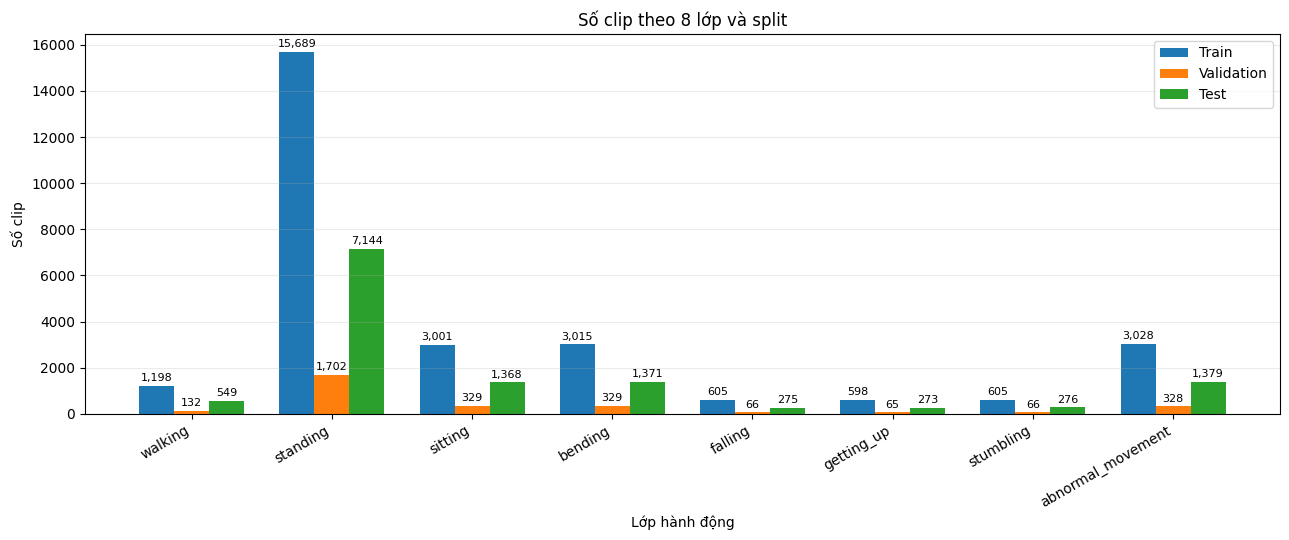

,class_id,class_name,train_clips,train_percent
0,0,walking,"1,198",4.32%
1,1,standing,"15,689",56.56%
2,2,sitting,"3,001",10.82%
3,3,bending,"3,015",10.87%
4,4,falling,605,2.18%
5,5,getting_up,598,2.16%
6,6,stumbling,605,2.18%
7,7,abnormal_movement,"3,028",10.92%


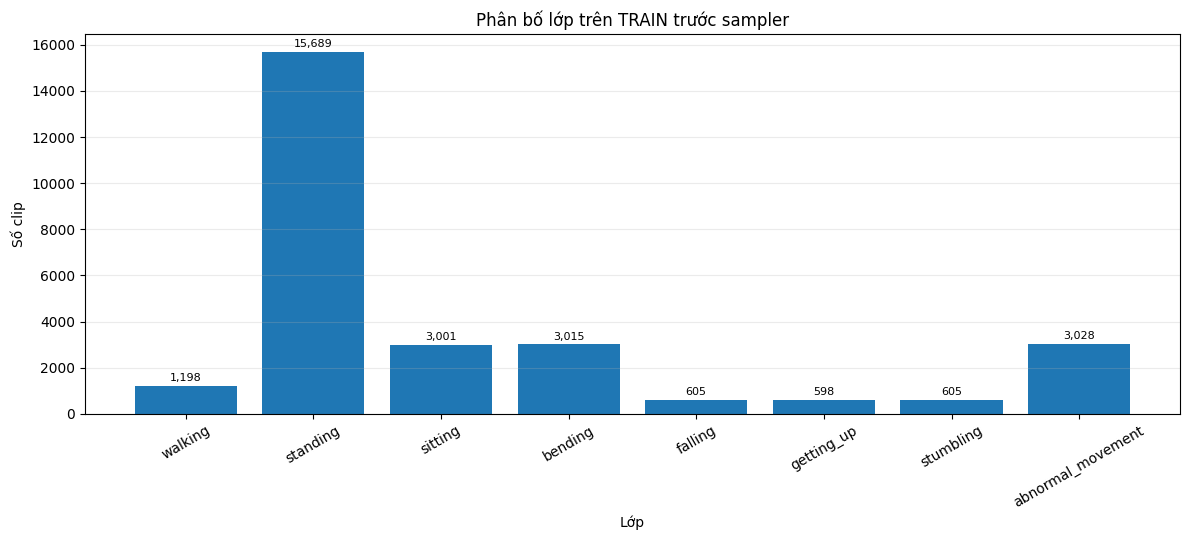

Train clip imbalance max/min = 26.24x


,Train,Validation,Test
COCO-17 joint,,,
nose,0.938,0.933,0.936
left_eye,0.932,0.927,0.929
right_eye,0.933,0.929,0.931
left_ear,0.841,0.837,0.843
right_ear,0.841,0.843,0.844
left_shoulder,0.868,0.865,0.871
right_shoulder,0.869,0.865,0.872
left_elbow,0.870,0.864,0.869
right_elbow,0.861,0.862,0.865


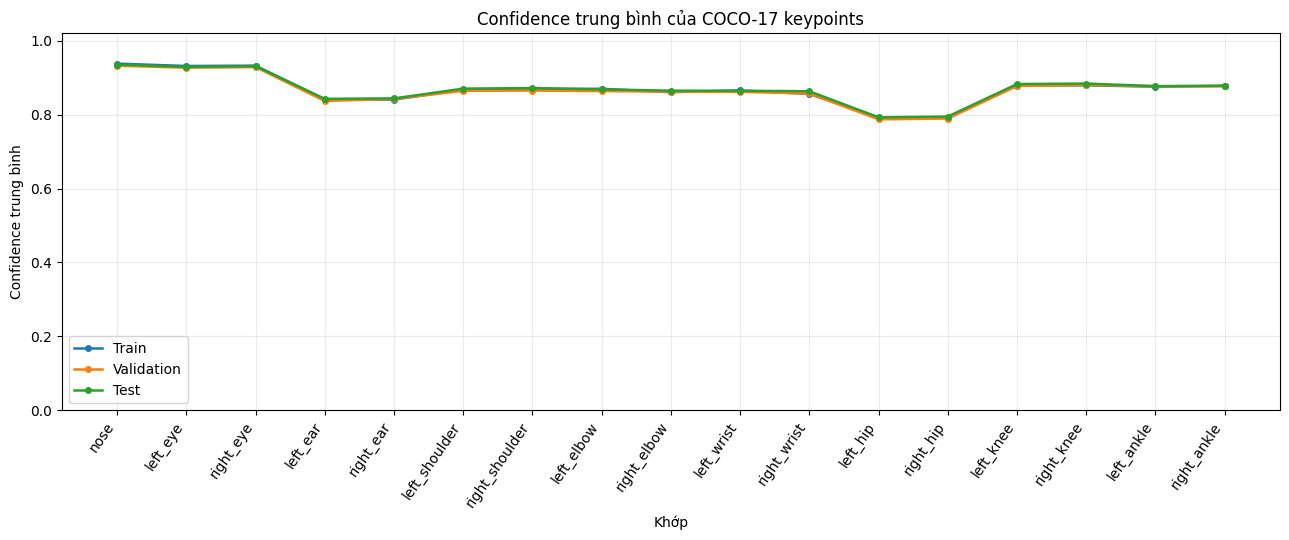

,split,clips,subjects,classes_present
0,Train,27739,17,8
1,Validation,3017,3,8
2,Test,12635,20,8


Split strategy: official xsub_train/xsub_val + subject-group
Samples are clips only; no overlapping windows are generated.


In [13]:
# ------------------ A. CLIP COUNTS BY CLASS / SPLIT ------------------
split_clip_indices = {"Train": list(train_idxs), "Validation": list(val_idxs), "Test": list(test_idxs)}
clip_rows = []
for split_name, idxs in split_clip_indices.items():
    split_meta_df = meta.loc[idxs]
    counts = split_meta_df["class_name"].value_counts()
    for class_name in CLASS_NAMES:
        clip_rows.append({"class_name": class_name, "split": split_name,
                          "clips": int(counts.get(class_name, 0))})
clip_counts_long = pd.DataFrame(clip_rows)
clip_counts_wide = (clip_counts_long.pivot(index="class_name", columns="split", values="clips")
                    .reindex(CLASS_NAMES).fillna(0).astype(int))
clip_counts_wide = clip_counts_wide.reindex(columns=["Train", "Validation", "Test"])
print("CLIPS PER CLASS / SPLIT")
display(clip_counts_wide.style.format("{:,}").set_caption("Nguồn clip theo lớp và split"))
clip_counts_long.to_csv(OUTPUT_DIR / "dataset_clip_counts_long.csv", index=False)
clip_counts_wide.to_csv(OUTPUT_DIR / "dataset_clip_counts_table.csv")

x = np.arange(len(CLASS_NAMES)); width = 0.25
fig, ax = plt.subplots(figsize=(13, 5.5))
for off, split_name in zip([-width, 0, width], ["Train", "Validation", "Test"]):
    values = clip_counts_wide[split_name].values
    bars = ax.bar(x + off, values, width, label=split_name)
    ax.bar_label(bars, labels=[f"{int(v):,}" if v else "" for v in values], padding=2, fontsize=8)
ax.set_title("Số clip theo 8 lớp và split"); ax.set_xlabel("Lớp hành động"); ax.set_ylabel("Số clip")
ax.set_xticks(x, CLASS_NAMES, rotation=30, ha="right"); ax.legend(); ax.grid(axis="y", alpha=.25)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "dataset_clip_counts.png", dpi=160, bbox_inches="tight"); plt.show()

# ------------------ B. CLASS IMBALANCE AT CLIP LEVEL ------------------
clip_train_counts = pd.Series(y_train).value_counts().reindex(range(NUM_CLASSES), fill_value=0)
train_class_balance = pd.DataFrame({"class_id": range(NUM_CLASSES), "class_name": CLASS_NAMES,
    "train_clips": clip_train_counts.values,
    "train_percent": 100.0 * clip_train_counts.values / max(len(y_train), 1)})
display(train_class_balance.style.format({"train_clips": "{:,}", "train_percent": "{:.2f}%"}))
train_class_balance.to_csv(OUTPUT_DIR / "dataset_train_class_imbalance.csv", index=False)
fig, ax = plt.subplots(figsize=(12, 5.5))
bars = ax.bar(CLASS_NAMES, clip_train_counts.values)
ax.bar_label(bars, labels=[f"{int(v):,}" for v in clip_train_counts.values], padding=2, fontsize=8)
ax.set_title("Phân bố lớp trên TRAIN trước sampler"); ax.set_xlabel("Lớp"); ax.set_ylabel("Số clip")
ax.tick_params(axis="x", rotation=30); ax.grid(axis="y", alpha=.25)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "dataset_train_class_imbalance.png", dpi=160, bbox_inches="tight"); plt.show()
imbalance_ratio = float(clip_train_counts.max() / max(clip_train_counts[clip_train_counts > 0].min(), 1))
print(f"Train clip imbalance max/min = {imbalance_ratio:.2f}x")

# ------------------ C. COCO-17 KEYPOINT CONFIDENCE ------------------
joint_names = ["nose", "left_eye", "right_eye", "left_ear", "right_ear",
    "left_shoulder", "right_shoulder", "left_elbow", "right_elbow", "left_wrist", "right_wrist",
    "left_hip", "right_hip", "left_knee", "right_knee", "left_ankle", "right_ankle"]

def mean_joint_confidence(X):
    conf = np.nan_to_num(np.asarray(X)[..., 34:51], nan=0.0, posinf=0.0, neginf=0.0)
    return conf.mean(axis=(0, 1))

confidence_df = pd.DataFrame({"Train": mean_joint_confidence(X_train),
    "Validation": mean_joint_confidence(X_val), "Test": mean_joint_confidence(X_test)}, index=joint_names)
confidence_df.index.name = "COCO-17 joint"
display(confidence_df.round(3).style.background_gradient(axis=None, vmin=0, vmax=1).format("{:.3f}"))
confidence_df.to_csv(OUTPUT_DIR / "dataset_keypoint_confidence.csv")
fig, ax = plt.subplots(figsize=(13, 5.5)); x = np.arange(len(joint_names))
for split_name in ["Train", "Validation", "Test"]:
    ax.plot(x, confidence_df[split_name].values, marker="o", linewidth=1.8, markersize=4, label=split_name)
ax.set_title("Confidence trung bình của COCO-17 keypoints"); ax.set_xlabel("Khớp"); ax.set_ylabel("Confidence trung bình")
ax.set_ylim(0, 1.02); ax.set_xticks(x, joint_names, rotation=55, ha="right"); ax.legend(); ax.grid(alpha=.25)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "dataset_keypoint_confidence.png", dpi=160, bbox_inches="tight"); plt.show()

# Split overview for reporting.
split_overview = []
for split_name, idxs in split_clip_indices.items():
    split_df = meta.loc[idxs]
    split_overview.append({"split": split_name, "clips": len(split_df),
        "subjects": int(split_df["subject"].nunique()), "classes_present": int(split_df["label"].nunique())})
split_overview_df = pd.DataFrame(split_overview)
display(split_overview_df)
split_overview_df.to_csv(OUTPUT_DIR / "dataset_split_overview.csv", index=False)
print("Split strategy:", split_mode)
print("Samples are clips only; no overlapping windows are generated.")


In [14]:
class SkeletonClipDataset(Dataset):
    """One fixed-length skeleton sequence and one label per source clip."""
    def __init__(self, X, y):
        self.X = torch.from_numpy(np.asarray(X, dtype=np.float32))
        self.y = torch.from_numpy(np.asarray(y, dtype=np.int64))
    def __len__(self): return len(self.y)
    def __getitem__(self, idx): return self.X[idx], self.y[idx]

train_ds = SkeletonClipDataset(X_train, y_train)
val_ds = SkeletonClipDataset(X_val, y_val)
test_ds = SkeletonClipDataset(X_test, y_test)

class_counts = np.bincount(y_train, minlength=NUM_CLASSES)
missing_train = [CLASS_NAMES[i] for i, n in enumerate(class_counts) if n == 0]
if missing_train:
    raise RuntimeError(f"Training split thiếu class: {missing_train}")
weights_per_class = 1.0 / class_counts.astype(np.float64)
sample_weights = weights_per_class[y_train]
train_sampler = WeightedRandomSampler(weights=torch.as_tensor(sample_weights, dtype=torch.double),
    num_samples=len(y_train), replacement=True)
loader_args = dict(num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"))
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=train_sampler, **loader_args)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, **loader_args)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, **loader_args)
print("Class counts before balanced sampler:")
for i, n in enumerate(class_counts): print(f"  {i}: {CLASS_NAMES[i]} = {int(n):,} clips")
print("Clips/samples per epoch:", len(train_sampler), "| train batches:", len(train_loader))


Class counts before balanced sampler:
  0: walking = 1,198 clips
  1: standing = 15,689 clips
  2: sitting = 3,001 clips
  3: bending = 3,015 clips
  4: falling = 605 clips
  5: getting_up = 598 clips
  6: stumbling = 605 clips
  7: abnormal_movement = 3,028 clips
Clips/samples per epoch: 27739 | train batches: 217


## 7. Dataset loader và cân bằng lớp

Mỗi sample trong train/validation/test đại diện cho một clip nguồn. `WeightedRandomSampler` được áp dụng **chỉ trên train** để cân bằng cơ hội lấy mẫu các lớp; validation và test giữ nguyên phân bố clip gốc. Dữ liệu không được oversample vào validation/test và không có window overlap.


In [15]:
class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0), persistent=False)
    def forward(self, x):
        return x + self.pe[:, :x.size(1)]


class TemporalTransformerClassifier(nn.Module):
    """Input [B,30,51] -> 8-class logits."""
    def __init__(self):
        super().__init__()
        self.input_proj = nn.Sequential(nn.Linear(FEATURE_DIM, D_MODEL), nn.LayerNorm(D_MODEL), nn.ReLU(), nn.Dropout(DROPOUT))
        self.positional = SinusoidalPositionalEncoding(D_MODEL)
        layer = nn.TransformerEncoderLayer(
            d_model=D_MODEL, nhead=NHEAD, dim_feedforward=DIM_FEEDFORWARD,
            dropout=DROPOUT, batch_first=True, activation="gelu", norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=NUM_TRANSFORMER_LAYERS)
        self.norm = nn.LayerNorm(D_MODEL)
        self.classifier = nn.Sequential(nn.Linear(D_MODEL, D_MODEL // 2), nn.GELU(),
                                        nn.Dropout(DROPOUT), nn.Linear(D_MODEL // 2, NUM_CLASSES))
    def forward(self, x):
        if x.ndim != 3 or x.shape[1:] != (SEQUENCE_LENGTH, FEATURE_DIM):
            raise ValueError(f"Expected [B,{SEQUENCE_LENGTH},{FEATURE_DIM}], got {tuple(x.shape)}")
        h = self.encoder(self.positional(self.input_proj(x)))
        return self.classifier(self.norm(h).mean(dim=1))


class RecurrentClassifier(nn.Module):
    def __init__(self, cell_type="LSTM", hidden_size=96, num_layers=2):
        super().__init__()
        rnn_cls = nn.LSTM if cell_type.upper() == "LSTM" else nn.GRU
        self.rnn = rnn_cls(input_size=FEATURE_DIM, hidden_size=hidden_size, num_layers=num_layers,
                           batch_first=True, bidirectional=True,
                           dropout=DROPOUT if num_layers > 1 else 0.0)
        self.norm = nn.LayerNorm(hidden_size * 2)
        self.classifier = nn.Sequential(nn.Linear(hidden_size * 2, 96), nn.GELU(),
                                        nn.Dropout(DROPOUT), nn.Linear(96, NUM_CLASSES))
    def forward(self, x):
        seq, _ = self.rnn(x)
        pooled = self.norm(seq.mean(dim=1))
        return self.classifier(pooled)


class TemporalConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, dilation, dropout=DROPOUT):
        super().__init__()
        pad = dilation  # kernel size = 3, stride = 1: keep temporal length
        self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size=3, padding=pad, dilation=dilation)
        self.bn1 = nn.BatchNorm1d(out_channels)
        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size=3, padding=pad, dilation=dilation)
        self.bn2 = nn.BatchNorm1d(out_channels)
        self.dropout = nn.Dropout(dropout)
        self.skip = nn.Identity() if in_channels == out_channels else nn.Conv1d(in_channels, out_channels, kernel_size=1)
    def forward(self, x):
        residual = self.skip(x)
        h = self.dropout(torch.nn.functional.gelu(self.bn1(self.conv1(x))))
        h = self.dropout(self.bn2(self.conv2(h)))
        return torch.nn.functional.gelu(h + residual)


class TCNClassifier(nn.Module):
    """Dilated residual temporal convolutions over [B,features,time]."""
    def __init__(self):
        super().__init__()
        channels = [64, 96, 128, 128]
        blocks = []; in_ch = FEATURE_DIM
        for out_ch, dilation in zip(channels, [1, 2, 4, 8]):
            blocks.append(TemporalConvBlock(in_ch, out_ch, dilation))
            in_ch = out_ch
        self.network = nn.Sequential(*blocks)
        self.classifier = nn.Sequential(nn.Linear(in_ch * 2, 128), nn.GELU(),
                                        nn.Dropout(DROPOUT), nn.Linear(128, NUM_CLASSES))
    def forward(self, x):
        h = self.network(x.transpose(1, 2))
        pooled = torch.cat([h.mean(dim=2), h.amax(dim=2)], dim=1)
        return self.classifier(pooled)


def build_model(name):
    if name == "Transformer": return TemporalTransformerClassifier()
    if name == "BiLSTM": return RecurrentClassifier("LSTM")
    if name == "BiGRU": return RecurrentClassifier("GRU")
    if name == "TCN": return TCNClassifier()
    raise ValueError(f"Model chưa được định nghĩa: {name}")

MODEL_BUILDERS = {name: (lambda n=name: build_model(n)) for name in MODEL_NAMES}
for model_name in MODEL_NAMES:
    candidate = build_model(model_name).to(DEVICE)
    with torch.no_grad():
        test_out = candidate(torch.zeros(2, SEQUENCE_LENGTH, FEATURE_DIM, device=DEVICE))
    params = sum(p.numel() for p in candidate.parameters() if p.requires_grad)
    print(f"{model_name:12s} | output={tuple(test_out.shape)} | trainable parameters={params:,}")
    del candidate
if DEVICE.type == "cuda": torch.cuda.empty_cache()

/tmp/ipykernel_50/2802500021.py:23: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(layer, num_layers=NUM_TRANSFORMER_LAYERS)


Transformer  | output=(2, 8) | trainable parameters=545,864
BiLSTM       | output=(2, 8) | trainable parameters=356,840
BiGRU        | output=(2, 8) | trainable parameters=272,552
TCN          | output=(2, 8) | trainable parameters=310,888


## 8. Huấn luyện bốn mô hình trên cùng các clip

Transformer, BiLSTM, BiGRU và TCN nhận đúng cùng một tensor đại diện cho mỗi clip `(30, 51)` và cùng nhãn clip. Các yếu tố dùng chung gồm split, sampler train, batch size, optimizer AdamW, learning rate, label smoothing, gradient clipping và tiêu chí dừng sớm.

Checkpoint được chọn theo **validation macro-F1 trên 8 lớp**. Test chỉ được dùng một lần để tạo bảng kết quả cuối. Mô hình có kiến trúc khác nhau nên notebook ghi số tham số và thời gian train; khi làm bài báo, nên lặp lại với nhiều seed và báo cáo trung bình ± độ lệch chuẩn.


In [16]:
amp_enabled = bool(USE_AMP and DEVICE.type == "cuda")

@torch.no_grad()
def evaluate_loss_and_predictions(model, loader, criterion):
    model.eval(); loss_sum = 0.0; n_seen = 0; ys = []; probs = []
    for xb, yb in loader:
        xb = xb.to(DEVICE, non_blocking=True)
        yb = yb.to(DEVICE, non_blocking=True).long()
        with torch.amp.autocast(device_type=DEVICE.type, enabled=amp_enabled):
            logits = model(xb)
            loss = criterion(logits, yb)
        p = torch.softmax(logits.float(), dim=1)
        loss_sum += float(loss.item()) * int(yb.size(0)); n_seen += int(yb.size(0))
        ys.append(yb.cpu().numpy()); probs.append(p.cpu().numpy())
    return loss_sum / max(n_seen, 1), np.concatenate(ys), np.concatenate(probs)


def train_one_model(model_name, model_index):
    # Reproducible initialization per model; same data order policy and training recipe.
    model_seed = SEED + model_index
    random.seed(model_seed); np.random.seed(model_seed); torch.manual_seed(model_seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(model_seed)

    # Reuse the exact same balanced-sampling index sequence for each architecture.
    train_sampler.generator = torch.Generator().manual_seed(SEED + 999)
    model = build_model(model_name).to(DEVICE)
    param_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
    criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=LEARNING_RATE,
        total_steps=max(1, NUM_EPOCHS * len(train_loader)), pct_start=0.10,
        anneal_strategy="cos", div_factor=10.0, final_div_factor=100.0)
    scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)
    best_f1 = -1.0; best_epoch = 0; no_improve = 0; records = []
    slug = model_name.lower()
    best_path = OUTPUT_DIR / f"best_{slug}_8class.pth"
    started = time.perf_counter()

    for epoch in range(1, NUM_EPOCHS + 1):
        model.train(); loss_sum = 0.0; n_seen = 0
        for xb, yb in tqdm(train_loader, desc=f"{model_name} epoch {epoch:02d}", leave=False):
            xb = xb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True).long()
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast(device_type=DEVICE.type, enabled=amp_enabled):
                logits = model(xb)
                loss = criterion(logits, yb)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer); scaler.update(); scheduler.step()
            n = int(yb.size(0)); loss_sum += float(loss.detach().item()) * n; n_seen += n

        train_loss = loss_sum / max(n_seen, 1)
        val_loss, yv, val_prob = evaluate_loss_and_predictions(model, val_loader, criterion)
        val_pred = val_prob.argmax(axis=1)
        val_macro_f1 = f1_score(yv, val_pred, labels=np.arange(NUM_CLASSES), average="macro", zero_division=0)
        val_acc = accuracy_score(yv, val_pred)
        records.append({"model": model_name, "epoch": epoch, "train_loss": train_loss,
                        "val_loss": val_loss, "val_macro_f1": float(val_macro_f1),
                        "val_accuracy": float(val_acc), "learning_rate": optimizer.param_groups[0]["lr"]})
        improved = val_macro_f1 > best_f1 + 1e-5
        if improved:
            best_f1 = float(val_macro_f1); best_epoch = epoch; no_improve = 0
            cpu_state = {k: v.detach().cpu() for k, v in model.state_dict().items()}
            torch.save({"model_state_dict": cpu_state, "model_name": model_name,
                        "epoch": epoch, "val_macro_f1": best_f1,
                        "class_names": CLASS_NAMES, "feature_dim": FEATURE_DIM,
                        "sequence_length": SEQUENCE_LENGTH, "action_groups": ACTION_GROUPS,
                        "seed": model_seed}, best_path)
        else:
            no_improve += 1
        print(f"{model_name:12s} epoch {epoch:02d}/{NUM_EPOCHS} | train_loss={train_loss:.4f} "
              f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} val_macroF1={val_macro_f1:.4f}"
              + ("  <-- BEST" if improved else ""))
        if no_improve >= EARLY_STOPPING_PATIENCE:
            print(f"Early stopping {model_name}: best epoch={best_epoch}, val macro-F1={best_f1:.4f}")
            break

    elapsed = time.perf_counter() - started
    hist = pd.DataFrame(records)
    hist.to_csv(OUTPUT_DIR / f"{slug}_training_history.csv", index=False)
    result = {"model": model_name, "params": int(param_count), "best_epoch": int(best_epoch),
              "best_val_macro_f1": float(best_f1), "training_seconds": float(elapsed),
              "checkpoint": str(best_path)}
    del model, optimizer, scheduler, scaler
    gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return hist, result

history_frames = []
training_summaries = []
for model_index, model_name in enumerate(MODEL_NAMES):
    print("\n" + "=" * 76 + f"\nTRAINING MODEL: {model_name}\n" + "=" * 76)
    hist, summary = train_one_model(model_name, model_index)
    history_frames.append(hist); training_summaries.append(summary)

history_df = pd.concat(history_frames, ignore_index=True)
history_df.to_csv(OUTPUT_DIR / "all_models_training_history.csv", index=False)
training_summary_df = pd.DataFrame(training_summaries)
training_summary_df.to_csv(OUTPUT_DIR / "training_summary_by_model.csv", index=False)
print("\nTraining summary:")
display(training_summary_df.style.format({"params": "{:,}", "best_epoch": "{:d}",
    "best_val_macro_f1": "{:.4f}", "training_seconds": "{:.1f}"}))


TRAINING MODEL: Transformer


/tmp/ipykernel_50/2802500021.py:23: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(layer, num_layers=NUM_TRANSFORMER_LAYERS)


Transformer epoch 01:   0%|          | 0/217 [00:00<?, ?it/s]

Transformer  epoch 01/30 | train_loss=1.4944 val_loss=1.4159 val_acc=0.3020 val_macroF1=0.5227  <-- BEST


Transformer epoch 02:   0%|          | 0/217 [00:00<?, ?it/s]

...

TCN epoch 26:   0%|          | 0/217 [00:00<?, ?it/s]

TCN          epoch 26/30 | train_loss=0.3130 val_loss=0.5680 val_acc=0.8800 val_macroF1=0.9108


TCN epoch 27:   0%|          | 0/217 [00:00<?, ?it/s]

TCN          epoch 27/30 | train_loss=0.3132 val_loss=0.5752 val_acc=0.8794 val_macroF1=0.9090
Early stopping TCN: best epoch=21, val macro-F1=0.9112

Training summary:


,model,params,best_epoch,best_val_macro_f1,training_seconds,checkpoint
0,Transformer,"545,864",21,0.8979,95.2,/kaggle/working/ntu60_8class_cliplevel_comparison/best_transformer_8class.pth
1,BiLSTM,"356,840",21,0.8787,51.1,/kaggle/working/ntu60_8class_cliplevel_comparison/best_bilstm_8class.pth
2,BiGRU,"272,552",22,0.8767,48.6,/kaggle/working/ntu60_8class_cliplevel_comparison/best_bigru_8class.pth
3,TCN,"310,888",21,0.9112,67.1,/kaggle/working/ntu60_8class_cliplevel_comparison/best_tcn_8class.pth


## 9. Đánh giá cuối cùng — chỉ cấp clip

Do mỗi clip sinh đúng một chuỗi input và một dự đoán, **không có đánh giá window-level** và không cần tổng hợp nhiều dự đoán để tính metric clip. Với cả bốn mô hình, notebook báo cáo trên cùng tập test clip:

- Accuracy và Balanced Accuracy.
- Macro Precision/Recall/F1 và Weighted-F1 trên đủ 8 lớp.
- Precision, Recall và F1 riêng lớp `falling`.
- Classification report và confusion matrix 8 × 8.
- Latency trung bình mỗi clip, clips/second và số tham số trainable.

Checkpoint được chọn bằng validation macro-F1. Không lựa chọn kiến trúc theo kết quả test.


In [17]:
@torch.no_grad()
def predict_model(model, loader):
    model.eval(); ys = []; probs = []
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    start = time.perf_counter()
    for xb, yb in loader:
        xb = xb.to(DEVICE, non_blocking=True)
        with torch.amp.autocast(device_type=DEVICE.type, enabled=amp_enabled):
            logits = model(xb)
        p = torch.softmax(logits.float(), dim=1)
        ys.append(yb.numpy()); probs.append(p.cpu().numpy())
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    return np.concatenate(ys), np.concatenate(probs), elapsed


def metric_summary(y_true, y_pred):
    fall_idx = CLASS_TO_IDX["falling"]
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "macro_precision": float(precision_score(y_true, y_pred, labels=np.arange(NUM_CLASSES), average="macro", zero_division=0)),
        "macro_recall": float(recall_score(y_true, y_pred, labels=np.arange(NUM_CLASSES), average="macro", zero_division=0)),
        "macro_f1": float(f1_score(y_true, y_pred, labels=np.arange(NUM_CLASSES), average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, labels=np.arange(NUM_CLASSES), average="weighted", zero_division=0)),
        "falling_precision": float(precision_score(y_true, y_pred, labels=[fall_idx], average="macro", zero_division=0)),
        "falling_recall": float(recall_score(y_true, y_pred, labels=[fall_idx], average="macro", zero_division=0)),
        "falling_f1": float(f1_score(y_true, y_pred, labels=[fall_idx], average="macro", zero_division=0)),
    }

model_predictions = {}
comparison_rows = []
per_class_rows = []
confusion_matrices = {}
training_summary_lookup = {row["model"]: row for row in training_summaries}

for model_name in MODEL_NAMES:
    slug = model_name.lower()
    ckpt_path = OUTPUT_DIR / f"best_{slug}_8class.pth"
    checkpoint = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
    model = build_model(model_name).to(DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"])
    test_true, test_probs, inference_seconds = predict_model(model, test_loader)
    test_pred = test_probs.argmax(axis=1)

    report_dict = classification_report(test_true, test_pred, labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    for class_name in CLASS_NAMES:
        row = report_dict[class_name]
        per_class_rows.append({"model": model_name, "class_name": class_name,
            "precision": row["precision"], "recall": row["recall"],
            "f1": row["f1-score"], "support": int(row["support"])})

    cm = confusion_matrix(test_true, test_pred, labels=np.arange(NUM_CLASSES))
    confusion_matrices[model_name] = cm
    np.save(OUTPUT_DIR / f"{slug}_confusion_matrix_clip.npy", cm)

    summary = {"model": model_name, **training_summary_lookup[model_name]}
    summary.pop("checkpoint", None)
    summary.update(metric_summary(test_true, test_pred))
    summary["test_clips"] = int(len(test_true))
    summary["inference_ms_per_clip"] = float(inference_seconds * 1000.0 / max(len(test_true), 1))
    summary["approx_clips_per_second"] = float(len(test_true) / max(inference_seconds, 1e-9))
    comparison_rows.append(summary)

    pred_df = pd.DataFrame({"clip_id": test_clip_ids,
        "y_true": test_true, "true_class": [CLASS_NAMES[int(i)] for i in test_true],
        "y_pred": test_pred, "pred_class": [CLASS_NAMES[int(i)] for i in test_pred]})
    for j, class_name in enumerate(CLASS_NAMES): pred_df[f"prob_{class_name}"] = test_probs[:, j]
    pred_df.to_csv(OUTPUT_DIR / f"{slug}_test_clip_predictions.csv", index=False)
    pd.DataFrame(report_dict).transpose().to_csv(OUTPUT_DIR / f"{slug}_classification_report_clip.csv")
    pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
        OUTPUT_DIR / f"{slug}_confusion_matrix_clip.csv", index_label="true_vs_pred")

    model_predictions[model_name] = {"y_true": test_true, "probabilities": test_probs, "y_pred": test_pred}
    print(f"\n=== {model_name}: TEST CLIP REPORT ===")
    print(classification_report(test_true, test_pred, labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES, digits=4, zero_division=0))
    del model, checkpoint
    gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(OUTPUT_DIR / "model_comparison_metrics.csv", index=False)
per_class_df = pd.DataFrame(per_class_rows)
per_class_df.to_csv(OUTPUT_DIR / "per_class_metrics_clip.csv", index=False)

comparison_cols = ["model", "params", "best_epoch", "best_val_macro_f1", "training_seconds",
    "accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1",
    "falling_precision", "falling_recall", "falling_f1", "inference_ms_per_clip", "approx_clips_per_second"]
print("\nMAIN RESULT — sorted by validation macro-F1; all TEST metrics are clip-level")
display(comparison_df[comparison_cols].sort_values("best_val_macro_f1", ascending=False).style.format({
    "params": "{:,}", "best_epoch": "{:.0f}", "best_val_macro_f1": "{:.4f}", "training_seconds": "{:.1f}",
    "accuracy": "{:.4f}", "balanced_accuracy": "{:.4f}", "macro_precision": "{:.4f}",
    "macro_recall": "{:.4f}", "macro_f1": "{:.4f}", "weighted_f1": "{:.4f}",
    "falling_precision": "{:.4f}", "falling_recall": "{:.4f}", "falling_f1": "{:.4f}",
    "inference_ms_per_clip": "{:.3f}", "approx_clips_per_second": "{:.1f}"
}))


/tmp/ipykernel_50/2802500021.py:23: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(layer, num_layers=NUM_TRANSFORMER_LAYERS)



=== Transformer: TEST CLIP REPORT ===
                   precision    recall  f1-score   support

          walking     0.9543    0.9891    0.9714       549
         standing     0.9598    0.8716    0.9136      7144
          sitting     0.7909    0.9678    0.8705      1368
          bending     0.7764    0.7622    0.7692      1371
          falling     0.9928    0.9964    0.9946       275
       getting_up     0.9926    0.9890    0.9908       273
        stumbling     0.9586    0.9239    0.9410       276
abnormal_movement     0.6915    0.8745    0.7723      1379

         accuracy                         0.8820     12635
        macro avg     0.8896    0.9218    0.9029     12635
     weighted avg     0.8935    0.8820    0.8844     12635


=== BiLSTM: TEST CLIP REPORT ===
                   precision    recall  f1-score   support

          walking     0.9415    0.9672    0.9542       549
         standing     0.9351    0.8575    0.8946      7144
          sitting     0.8681    0.8947

,model,params,best_epoch,best_val_macro_f1,training_seconds,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,falling_precision,falling_recall,falling_f1,inference_ms_per_clip,approx_clips_per_second
3,TCN,"310,888",21,0.9112,67.1,0.8996,0.9303,0.9096,0.9303,0.9177,0.9023,0.9963,0.9891,0.9927,0.028,35834.2
0,Transformer,"545,864",21,0.8979,95.2,0.8820,0.9218,0.8896,0.9218,0.9029,0.8844,0.9928,0.9964,0.9946,0.036,27950.1
1,BiLSTM,"356,840",21,0.8787,51.1,0.8602,0.8974,0.8690,0.8974,0.8815,0.8638,0.9855,0.9891,0.9873,0.023,42729.8
2,BiGRU,"272,552",22,0.8767,48.6,0.8544,0.9025,0.8670,0.9025,0.8825,0.8575,0.9751,0.9964,0.9856,0.021,47103.5


## 10. Báo cáo test, dự đoán từng clip và confusion matrix

Xuất classification report 8 lớp, một hàng cho mỗi clip test gồm nhãn thật/dự đoán và xác suất 8 lớp, cùng confusion matrix thô. Với ứng dụng an toàn, cần xem riêng Recall của `falling` (clip té ngã bị bỏ sót) và Precision của `falling` (dự đoán té ngã bị báo nhầm).


In [18]:
# Recreate a concise, explicit set of clip-level reporting artifacts.
for model_name in MODEL_NAMES:
    slug = model_name.lower()
    pred_info = model_predictions[model_name]
    y_true, y_pred = pred_info["y_true"], pred_info["y_pred"]
    report = classification_report(y_true, y_pred, labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    pd.DataFrame(report).transpose().to_csv(OUTPUT_DIR / f"{slug}_classification_report_clip.csv")
    pd.DataFrame(confusion_matrices[model_name], index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
        OUTPUT_DIR / f"{slug}_confusion_matrix_clip.csv", index_label="true_vs_pred")

split_summary = {
    "split_strategy": split_mode,
    "sample_unit": "one source clip = one sample = one prediction",
    "class_names": CLASS_NAMES,
    "action_groups": {k: list(v) for k, v in ACTION_GROUPS.items()},
    "num_classes": NUM_CLASSES,
    "sequence_length": SEQUENCE_LENGTH,
    "feature_dim": FEATURE_DIM,
    "feature_layout": "normalized COCO-17 xy (34) + confidence (17)",
    "temporal_resampling": "uniform temporal interpolation across each complete clip",
    "batch_size": BATCH_SIZE,
    "epochs_requested": NUM_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "seed": SEED,
    "models": MODEL_NAMES,
    "synthetic_classes": [],
    "evaluation": "clip-level only; no sliding windows or window-level metrics",
    "note": "8-class action-group experiment; not the full standard 60-class NTU benchmark."
}
with open(OUTPUT_DIR / "experiment_config.json", "w", encoding="utf-8") as f:
    json.dump(split_summary, f, indent=2, ensure_ascii=False)
print("Saved clip-level metrics, predictions and confusion matrices to:", OUTPUT_DIR)


Saved clip-level metrics, predictions and confusion matrices to: /kaggle/working/ntu60_8class_cliplevel_comparison


## 11. Biểu đồ so sánh mô hình — cấp clip chỉ

Mỗi điểm test trong các biểu đồ tương ứng với một clip nguồn. Bao gồm đường cong train/validation, các metric tổng hợp, metric riêng lớp té ngã, confusion matrix chuẩn hóa, độ phức tạp mô hình và tốc độ suy luận trên mỗi clip.


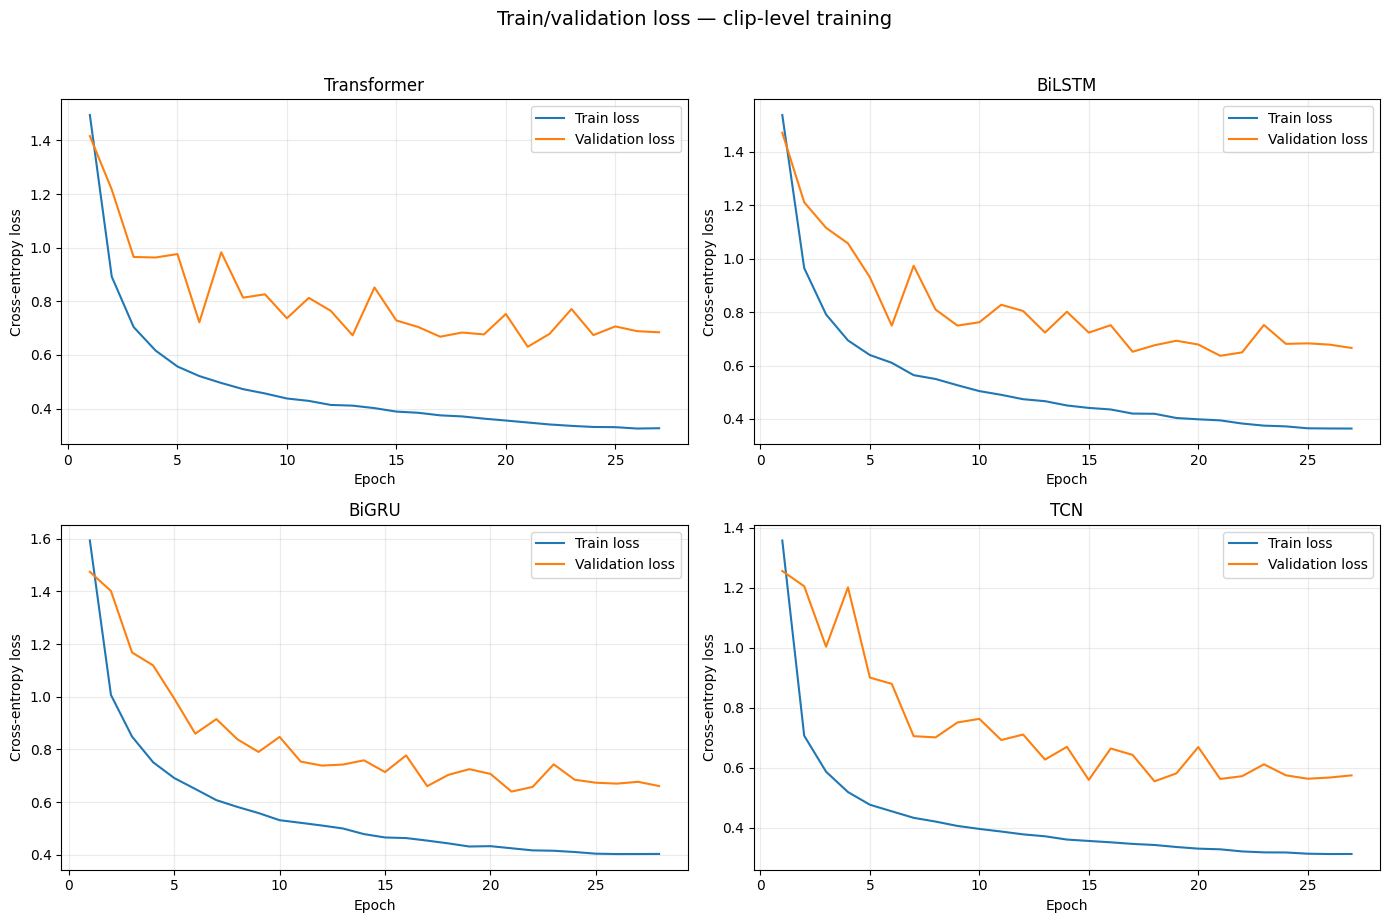

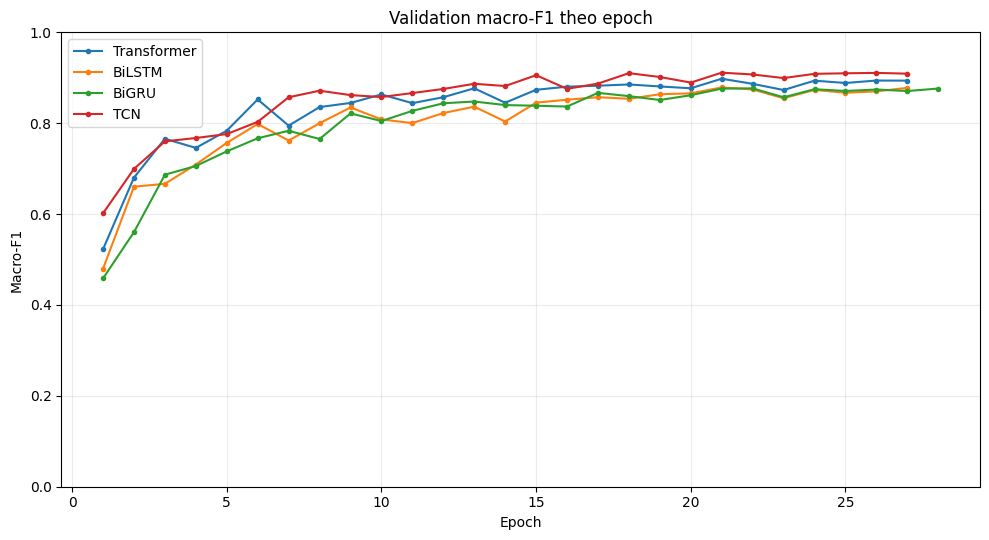

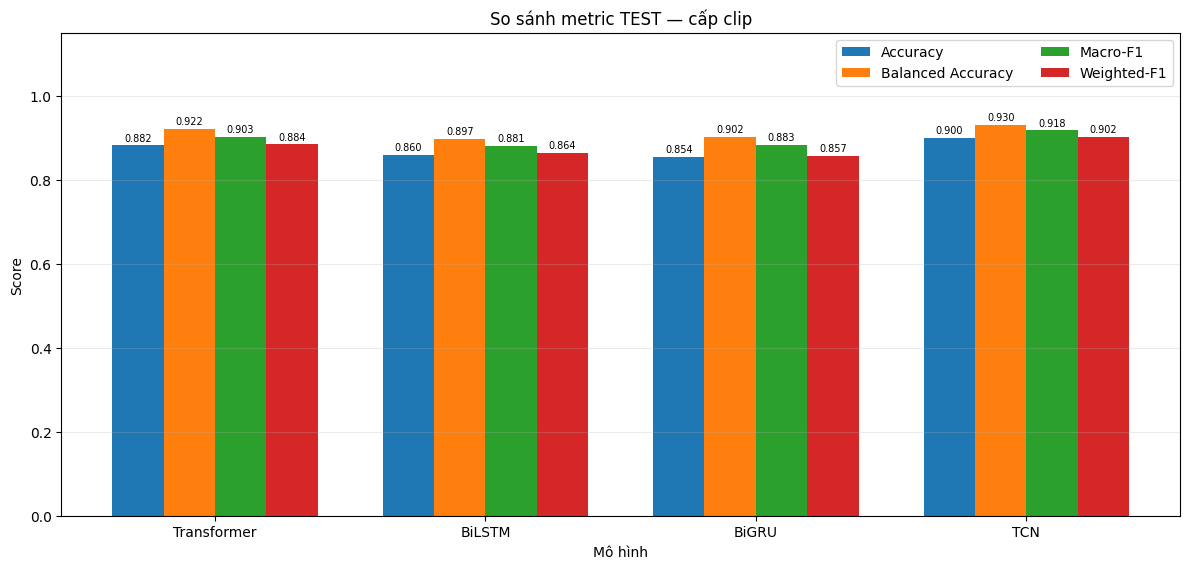

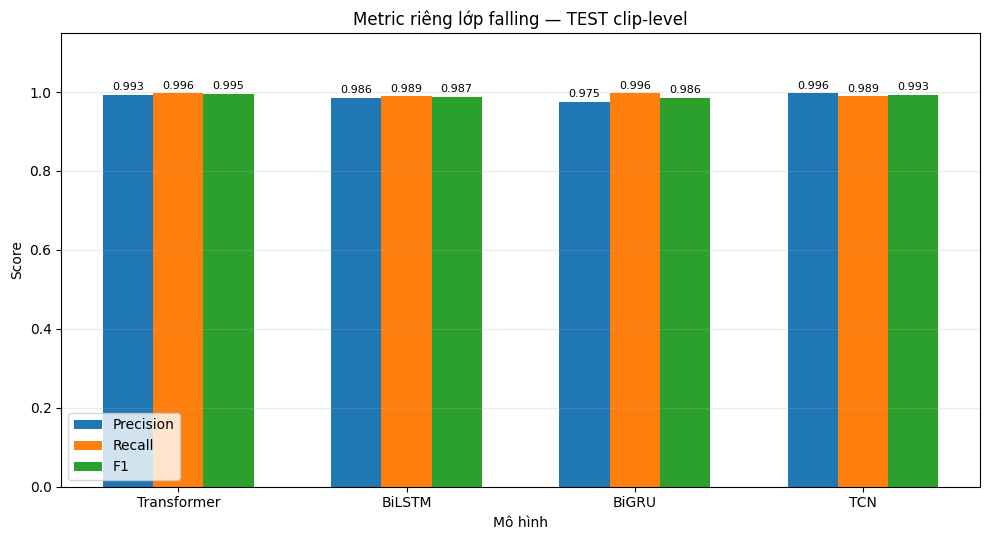

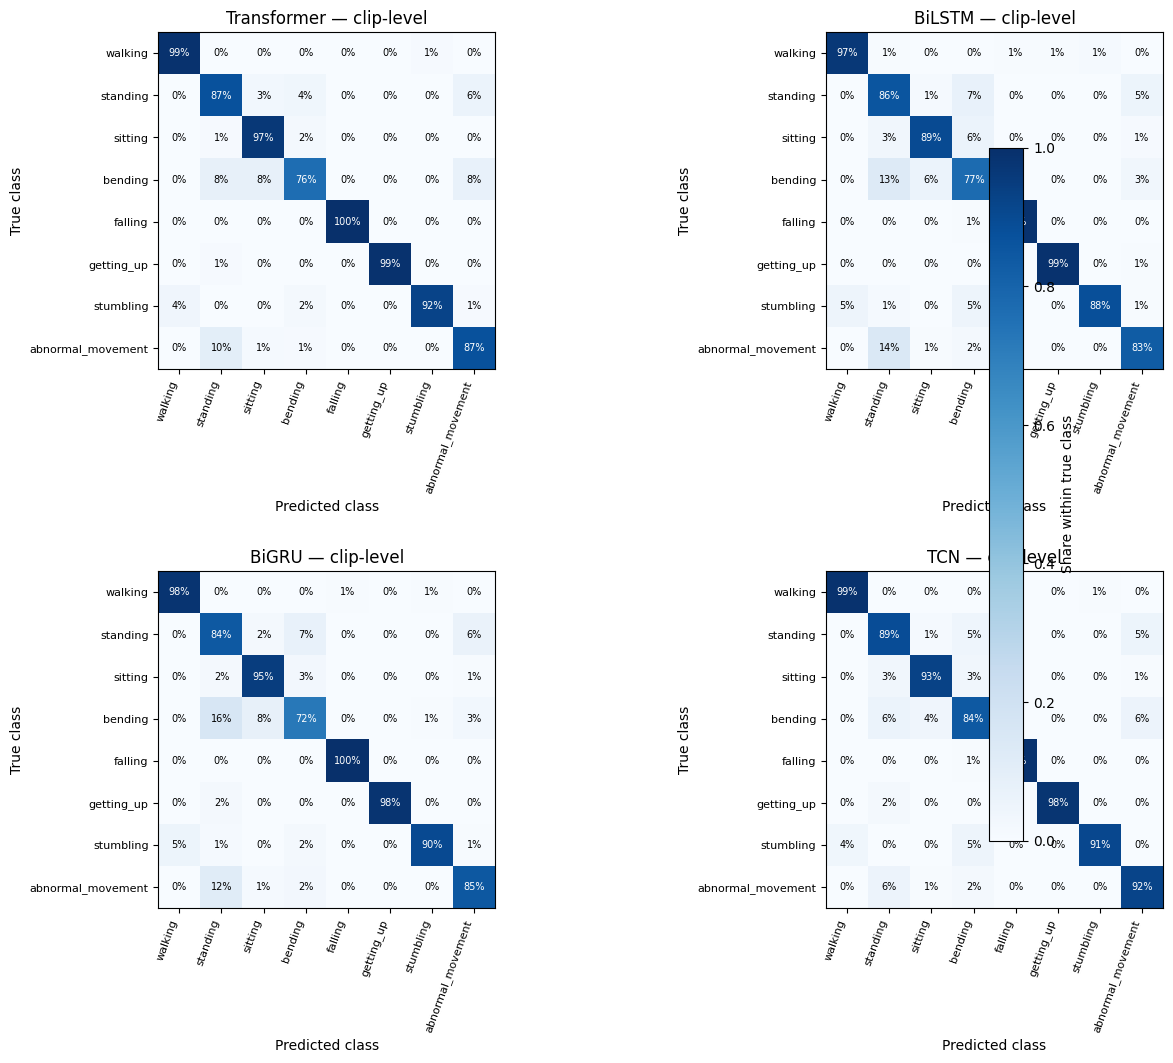

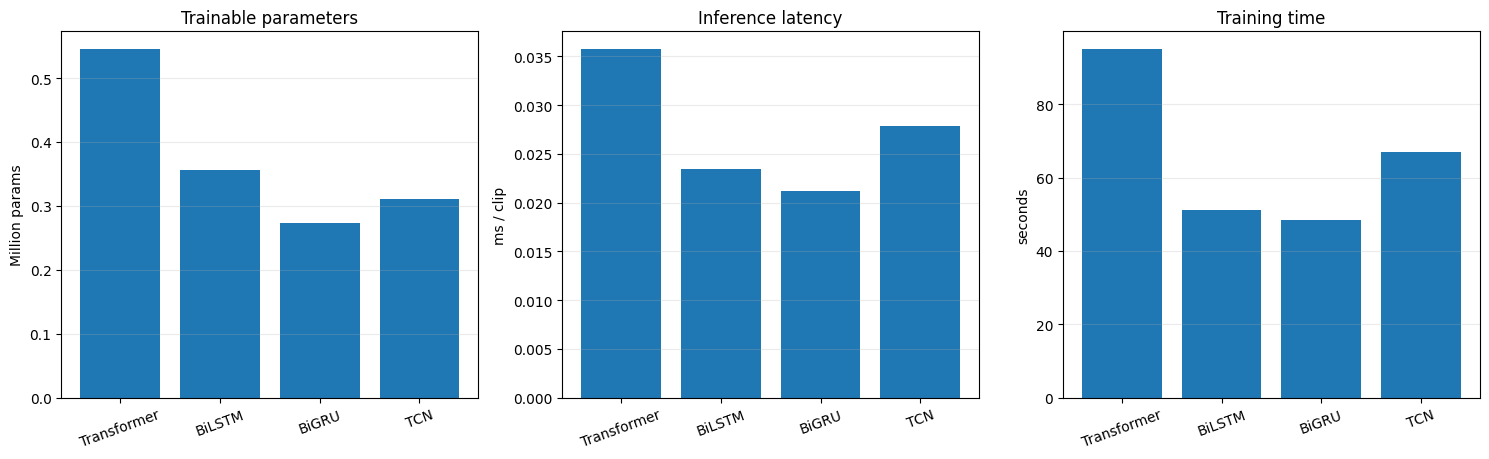

In [19]:
# A. Training/validation dynamics
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, model_name in zip(axes.flat, MODEL_NAMES):
    h = history_df[history_df.model == model_name]
    ax.plot(h.epoch, h.train_loss, label="Train loss")
    ax.plot(h.epoch, h.val_loss, label="Validation loss")
    ax.set_title(model_name); ax.set_xlabel("Epoch"); ax.set_ylabel("Cross-entropy loss")
    ax.grid(alpha=.25); ax.legend()
fig.suptitle("Train/validation loss — clip-level training", y=1.02, fontsize=14)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "comparison_training_validation_loss.png", dpi=170, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(10, 5.5))
for model_name in MODEL_NAMES:
    h = history_df[history_df.model == model_name]
    ax.plot(h.epoch, h.val_macro_f1, marker="o", markersize=3, label=model_name)
ax.set_title("Validation macro-F1 theo epoch"); ax.set_xlabel("Epoch"); ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1); ax.grid(alpha=.25); ax.legend()
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "comparison_validation_macro_f1.png", dpi=170, bbox_inches="tight"); plt.show()

# B. Main clip-level TEST metrics
main_metrics = [("accuracy", "Accuracy"), ("balanced_accuracy", "Balanced Accuracy"),
                ("macro_f1", "Macro-F1"), ("weighted_f1", "Weighted-F1")]
x = np.arange(len(MODEL_NAMES)); width = 0.19
fig, ax = plt.subplots(figsize=(12, 5.8))
for j, (col, label) in enumerate(main_metrics):
    vals = [float(comparison_df.loc[comparison_df.model == m, col].iloc[0]) for m in MODEL_NAMES]
    bars = ax.bar(x + (j - 1.5) * width, vals, width, label=label)
    ax.bar_label(bars, labels=[f"{v:.3f}" for v in vals], padding=2, fontsize=7)
ax.set_title("So sánh metric TEST — cấp clip"); ax.set_xlabel("Mô hình"); ax.set_ylabel("Score")
ax.set_ylim(0, 1.15); ax.set_xticks(x, MODEL_NAMES); ax.legend(ncol=2); ax.grid(axis="y", alpha=.25)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "comparison_clip_main_metrics.png", dpi=170, bbox_inches="tight"); plt.show()

# C. Falling-class metrics
fall_metrics = [("falling_precision", "Precision"), ("falling_recall", "Recall"), ("falling_f1", "F1")]
fig, ax = plt.subplots(figsize=(10, 5.5)); width = .22
for j, (col, label) in enumerate(fall_metrics):
    vals = [float(comparison_df.loc[comparison_df.model == m, col].iloc[0]) for m in MODEL_NAMES]
    bars = ax.bar(x + (j - 1) * width, vals, width, label=label)
    ax.bar_label(bars, labels=[f"{v:.3f}" for v in vals], padding=2, fontsize=8)
ax.set_title("Metric riêng lớp falling — TEST clip-level"); ax.set_xlabel("Mô hình"); ax.set_ylabel("Score")
ax.set_ylim(0, 1.15); ax.set_xticks(x, MODEL_NAMES); ax.legend(); ax.grid(axis="y", alpha=.25)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "comparison_clip_falling_metrics.png", dpi=170, bbox_inches="tight"); plt.show()

# D. Clip-level normalized confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for ax, model_name in zip(axes.flat, MODEL_NAMES):
    cm = confusion_matrices[model_name].astype(float)
    row_sum = cm.sum(axis=1, keepdims=True)
    cm_norm = np.divide(cm, row_sum, out=np.zeros_like(cm), where=row_sum > 0)
    im = ax.imshow(cm_norm, vmin=0, vmax=1, cmap="Blues")
    ax.set_title(f"{model_name} — clip-level")
    ax.set_xticks(range(NUM_CLASSES), labels=CLASS_NAMES, rotation=70, ha="right", fontsize=8)
    ax.set_yticks(range(NUM_CLASSES), labels=CLASS_NAMES, fontsize=8)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
    for r in range(NUM_CLASSES):
        for c in range(NUM_CLASSES):
            txt = f"{cm_norm[r,c]:.0%}" if row_sum[r,0] > 0 else "n/a"
            ax.text(c, r, txt, ha="center", va="center", fontsize=7,
                    color="white" if cm_norm[r,c] > .5 else "black")
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=.75, label="Share within true class")
fig.subplots_adjust(hspace=.6, wspace=.35, bottom=.15)
fig.savefig(OUTPUT_DIR / "comparison_clip_confusion_matrices_normalized.png", dpi=170, bbox_inches="tight"); plt.show()

# E. Trainable parameters, training duration, and clip inference throughput
fig, axes = plt.subplots(1, 3, figsize=(15, 4.7))
params_m = [float(comparison_df.loc[comparison_df.model == m, "params"].iloc[0]) / 1e6 for m in MODEL_NAMES]
latency = [float(comparison_df.loc[comparison_df.model == m, "inference_ms_per_clip"].iloc[0]) for m in MODEL_NAMES]
training_secs = [float(comparison_df.loc[comparison_df.model == m, "training_seconds"].iloc[0]) for m in MODEL_NAMES]
axes[0].bar(MODEL_NAMES, params_m); axes[0].set_title("Trainable parameters"); axes[0].set_ylabel("Million params")
axes[1].bar(MODEL_NAMES, latency); axes[1].set_title("Inference latency"); axes[1].set_ylabel("ms / clip")
axes[2].bar(MODEL_NAMES, training_secs); axes[2].set_title("Training time"); axes[2].set_ylabel("seconds")
for ax in axes: ax.tick_params(axis="x", rotation=20); ax.grid(axis="y", alpha=.25)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "comparison_model_size_latency_training_time.png", dpi=170, bbox_inches="tight"); plt.show()


## 11A. Báo cáo metric riêng từng lớp

Bảng này báo cáo Precision, Recall, F1 và Support của từng lớp ở **cấp clip**, cho phép đánh giá cả lớp phổ biến và lớp khó. Cần xem kỹ `falling` và các lớp có thể bị nhầm lẫn về chuyển động như `bending`, `getting_up` và `stumbling`.


CLIP-LEVEL F1 BY CLASS


model,Transformer,BiLSTM,BiGRU,TCN
class_name,,,,
walking,0.971,0.954,0.967,0.985
standing,0.914,0.895,0.886,0.926
sitting,0.870,0.881,0.879,0.907
bending,0.769,0.690,0.672,0.786
falling,0.995,0.987,0.986,0.993
getting_up,0.991,0.989,0.991,0.989
stumbling,0.941,0.885,0.914,0.942
abnormal_movement,0.772,0.770,0.766,0.815


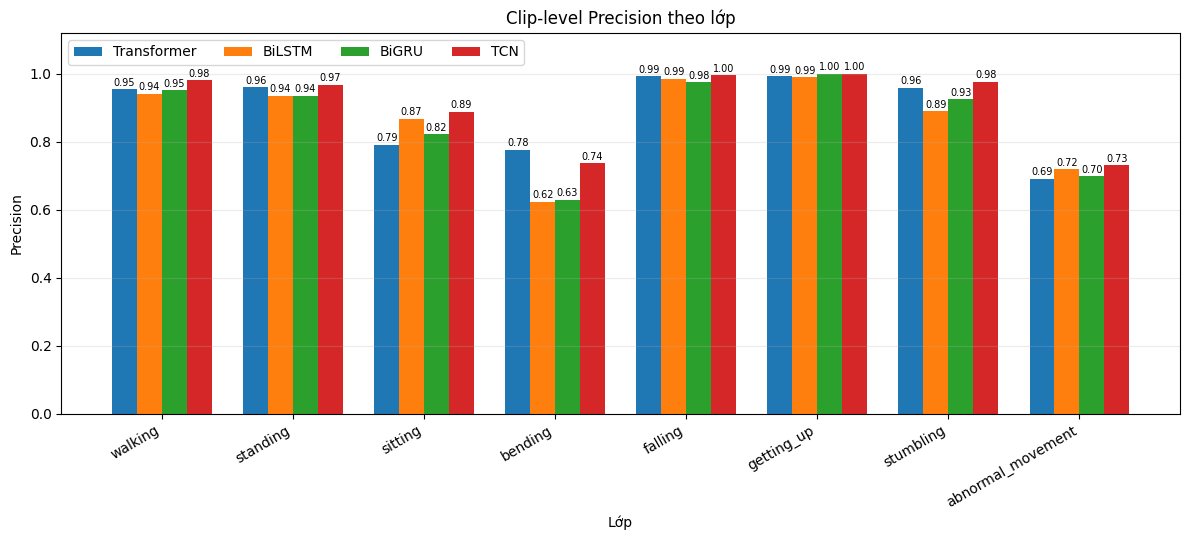

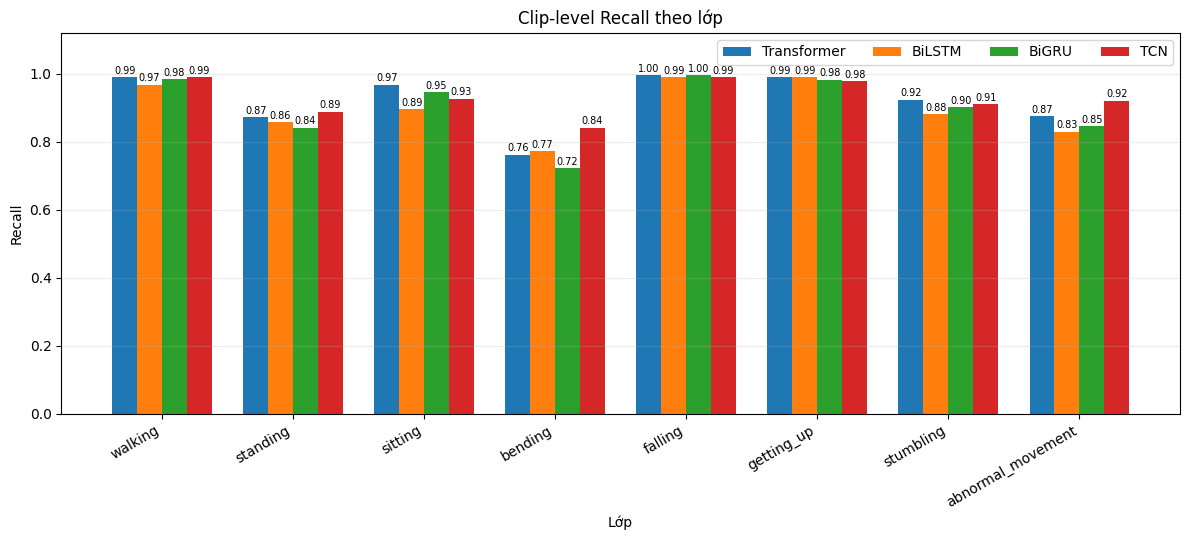

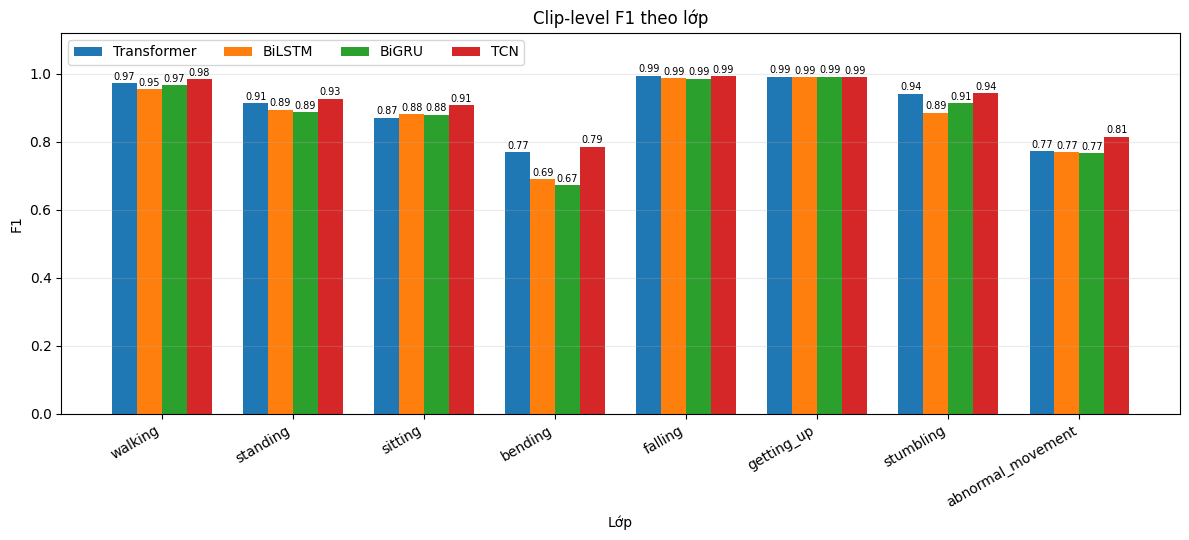


FINAL COMPARISON TABLE — TEST CLIPS ONLY


,model,params,best_epoch,best_val_macro_f1,accuracy,balanced_accuracy,macro_f1,weighted_f1,falling_precision,falling_recall,falling_f1,training_seconds,inference_ms_per_clip,approx_clips_per_second
3,TCN,"310,888",21,0.9112,0.8996,0.9303,0.9177,0.9023,0.9963,0.9891,0.9927,67.1,0.028,35834.2
0,Transformer,"545,864",21,0.8979,0.8820,0.9218,0.9029,0.8844,0.9928,0.9964,0.9946,95.2,0.036,27950.1
1,BiLSTM,"356,840",21,0.8787,0.8602,0.8974,0.8815,0.8638,0.9855,0.9891,0.9873,51.1,0.023,42729.8
2,BiGRU,"272,552",22,0.8767,0.8544,0.9025,0.8825,0.8575,0.9751,0.9964,0.9856,48.6,0.021,47103.5


Primary model-selection metric: validation macro-F1; test metrics are for final reporting only.


In [20]:
# Clip-level per-class metrics
clip_f1_pivot = per_class_df.pivot(index="class_name", columns="model", values="f1").reindex(CLASS_NAMES)
clip_f1_pivot = clip_f1_pivot.reindex(columns=MODEL_NAMES)
print("CLIP-LEVEL F1 BY CLASS")
display(clip_f1_pivot.style.format("{:.3f}").background_gradient(axis=None, vmin=0, vmax=1))
clip_f1_pivot.to_csv(OUTPUT_DIR / "comparison_clip_f1_by_class.csv")

for metric in ["precision", "recall", "f1"]:
    pivot = per_class_df.pivot(index="class_name", columns="model", values=metric).reindex(CLASS_NAMES)[MODEL_NAMES]
    fig, ax = plt.subplots(figsize=(12, 5.5))
    x_cls = np.arange(NUM_CLASSES); width = .19
    for j, model_name in enumerate(MODEL_NAMES):
        bars = ax.bar(x_cls + (j - 1.5) * width, pivot[model_name].values, width, label=model_name)
        ax.bar_label(bars, labels=[f"{v:.2f}" for v in pivot[model_name].values], padding=1, fontsize=7)
    ax.set_title(f"Clip-level {metric.title()} theo lớp"); ax.set_xlabel("Lớp"); ax.set_ylabel(metric.title())
    ax.set_ylim(0, 1.12); ax.set_xticks(x_cls, CLASS_NAMES, rotation=30, ha="right")
    ax.legend(ncol=4); ax.grid(axis="y", alpha=.25)
    fig.tight_layout(); fig.savefig(OUTPUT_DIR / f"comparison_clip_{metric}_by_class.png", dpi=170, bbox_inches="tight"); plt.show()

print("\nFINAL COMPARISON TABLE — TEST CLIPS ONLY")
final_cols = ["model", "params", "best_epoch", "best_val_macro_f1", "accuracy", "balanced_accuracy",
    "macro_f1", "weighted_f1", "falling_precision", "falling_recall", "falling_f1",
    "training_seconds", "inference_ms_per_clip", "approx_clips_per_second"]
display(comparison_df[final_cols].sort_values("best_val_macro_f1", ascending=False).style.format({
    "params": "{:,}", "best_epoch": "{:.0f}", "best_val_macro_f1": "{:.4f}",
    "accuracy": "{:.4f}", "balanced_accuracy": "{:.4f}", "macro_f1": "{:.4f}",
    "weighted_f1": "{:.4f}", "falling_precision": "{:.4f}", "falling_recall": "{:.4f}",
    "falling_f1": "{:.4f}", "training_seconds": "{:.1f}", "inference_ms_per_clip": "{:.3f}",
    "approx_clips_per_second": "{:.1f}"
}))
print("Primary model-selection metric: validation macro-F1; test metrics are for final reporting only.")


## 12. Lưu cấu hình và đóng gói kết quả

Notebook lưu checkpoint 8 lớp của từng kiến trúc, config, split manifest, lịch sử train, metric tổng hợp, classification reports, dự đoán từng clip, confusion matrices, bảng thống kê clip và PNG của tất cả biểu đồ. Không xuất window-level report hay window-level predictions.


In [21]:
final_config = {
    "task": "ntu60_mapped_8_class_clip_level_skeleton_action_recognition",
    "sample_unit": "one source clip = one sample = one prediction",
    "evaluation_level": "clip_only_no_window_metrics",
    "class_names": CLASS_NAMES,
    "class_to_idx": CLASS_TO_IDX,
    "action_groups": {name: list(ids) for name, ids in ACTION_GROUPS.items()},
    "dataset_file": "ntu60_2d.pkl",
    "split_strategy": split_mode,
    "input": {
        "keypoints": "COCO-17 2D",
        "sequence_length": SEQUENCE_LENGTH,
        "feature_dim": FEATURE_DIM,
        "feature_layout": "34 normalized xy coordinates + 17 keypoint confidence values",
        "temporal_resampling": "uniform linear resampling over the complete clip to 30 timestamps",
        "normalization": "one hip-origin + median torso-length scale shared over the sampled clip",
        "confidence_threshold": KEYPOINT_CONF_THRESHOLD,
    },
    "models": {
        "Transformer": "linear projection + sinusoidal positional encoding + Transformer Encoder + temporal mean pooling",
        "BiLSTM": "2-layer bidirectional LSTM + temporal mean pooling",
        "BiGRU": "2-layer bidirectional GRU + temporal mean pooling",
        "TCN": "4 residual temporal-convolution blocks, dilations=[1,2,4,8], mean+max pooling",
    },
    "training": {
        "epochs_requested": NUM_EPOCHS,
        "batch_size": BATCH_SIZE,
        "optimizer": "AdamW",
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "label_smoothing": LABEL_SMOOTHING,
        "early_stopping_patience": EARLY_STOPPING_PATIENCE,
        "sampling": "WeightedRandomSampler on training clips only",
        "model_selection": "highest validation macro-F1 over all 8 classes",
        "seed": SEED,
        "mixed_precision": amp_enabled,
    },
    "reported_metrics": ["accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1", "falling_precision", "falling_recall", "falling_f1"],
    "limitations": [
        "Eight grouped action classes, not the full standard 60-class NTU task.",
        "One uniformly resampled sequence per clip may downsample short temporal events in long clips.",
        "One random seed by default; repeat with multiple seeds and report mean +/- standard deviation for a paper.",
        "Latency is measured inside this notebook runtime and is not a full camera/pose-estimation deployment benchmark.",
        "Multiclass action recognition with a falling class is not the same as a dedicated binary fall-vs-non-fall benchmark."
    ],
}
with open(OUTPUT_DIR / "experiment_config.json", "w", encoding="utf-8") as f:
    json.dump(final_config, f, indent=2, ensure_ascii=False)

zip_path = Path("/kaggle/working/ntu60_8class_cliplevel_comparison_results.zip")
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for p in sorted(OUTPUT_DIR.rglob("*")):
        if p.is_file() and p != zip_path:
            zf.write(p, arcname=f"ntu60_8class_cliplevel_comparison/{p.relative_to(OUTPUT_DIR)}")

print("\nOUTPUT DIRECTORY:", OUTPUT_DIR)
print("RESULT ZIP:", zip_path)
print("Main summary:", OUTPUT_DIR / "model_comparison_metrics.csv")
print("Result files generated:")
for p in sorted(OUTPUT_DIR.iterdir()):
    if p.is_file(): print(f" - {p.name}: {p.stat().st_size / (1024**2):.2f} MB")



OUTPUT DIRECTORY: /kaggle/working/ntu60_8class_cliplevel_comparison
RESULT ZIP: /kaggle/working/ntu60_8class_cliplevel_comparison_results.zip
Main summary: /kaggle/working/ntu60_8class_cliplevel_comparison/model_comparison_metrics.csv
Result files generated:
 - all_models_training_history.csv: 0.01 MB
 - best_bigru_8class.pth: 1.05 MB
 - best_bilstm_8class.pth: 1.37 MB
 - best_tcn_8class.pth: 1.21 MB
 - best_transformer_8class.pth: 2.10 MB
 - bigru_classification_report_clip.csv: 0.00 MB
 - bigru_confusion_matrix_clip.csv: 0.00 MB
 - bigru_confusion_matrix_clip.npy: 0.00 MB
 - bigru_test_clip_predictions.csv: 1.70 MB
 - bigru_training_history.csv: 0.00 MB
 - bilstm_classification_report_clip.csv: 0.00 MB
 - bilstm_confusion_matrix_clip.csv: 0.00 MB
 - bilstm_confusion_matrix_clip.npy: 0.00 MB
 - bilstm_test_clip_predictions.csv: 1.70 MB
 - bilstm_training_history.csv: 0.00 MB
 - comparison_clip_confusion_matrices_normalized.png: 0.26 MB
 - comparison_clip_f1_by_class.csv: 0.00 MB
 - c